# Ambar Company: limpieza y análisis descriptivo de ventas

**Proyecto final · Introducción a la Ciencia de Datos**

**Integrantes:**

- Max Ayrton Vásquez Ruiz
- Luz Gabriela Cochachin Camacllanqui
- Brayan Luis Carpio Alegre
- Alexander Navas Rivadeneyra
- Danny Daniela Relaiza Bances

Notebook con todo el proceso: plan de trabajo, revisión y calidad del dataset, limpieza, transformación, estadística descriptiva, visualización e interpretación de hallazgos.

Se ejecuta en orden, de arriba hacia abajo (*Run All*), en Jupyter local o en Google Colab.

## 0. Configuración

Librerías, rutas de entrada y salida, y estilo común de los gráficos. En Google Colab, si el CSV no está, la celda pide subir `ARCHIVO_SL.csv`.

In [1]:
import json
import sys
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

EN_COLAB = "google.colab" in sys.modules

RAIZ = Path.cwd()
SL = RAIZ / "datos" / "SL" / "ARCHIVO_SL.csv"
CL = RAIZ / "datos" / "CL" / "ARCHIVO_CL.csv"
REPORTE = RAIZ / "reporte" / "REPORTE_NO_CORREGIDOS.csv"
GRAFICOS = RAIZ / "graficos"

# En Colab el CSV no viene con el notebook: se sube desde la PC
if EN_COLAB and not SL.exists():
    from google.colab import files

    print("Seleccione el archivo ARCHIVO_SL.csv")
    subido = files.upload()
    SL.parent.mkdir(parents=True, exist_ok=True)
    SL.write_bytes(next(iter(subido.values())))

for carpeta in (CL.parent, REPORTE.parent, GRAFICOS):
    carpeta.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
print(f"pandas {pd.__version__} | numpy {np.__version__} | seaborn {sns.__version__}")

pandas 3.1.1 | numpy 2.5.5 | seaborn 0.13.2


In [2]:
# Paleta fija: cada entidad conserva su color en todos los gráficos
TINTA, TINTA_2, TENUE = "#0b0b0b", "#52514e", "#898781"
GRILLA, FONDO, GRIS = "#e1e0d9", "#fcfcfb", "#c3c2b7"
AZUL, AZUL_CLARO, ROJO = "#2a78d6", "#86b6ef", "#e34948"

COLOR_CANAL = {"Tienda física": "#2a78d6", "Web": "#eb6834", "App móvil": "#1baf7a"}
COLOR_PAGO = {"Tarjeta": "#2a78d6", "Yape": "#eb6834", "Efectivo": "#1baf7a",
              "Plin": "#eda100", "PagoEfectivo": "#e87ba4"}
COLOR_SENTIMIENTO = {"Positivo": AZUL, "Neutral": "#a8a69e", "Negativo": ROJO}

SECUENCIAL = LinearSegmentedColormap.from_list(
    "azul", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIVERGENTE = LinearSegmentedColormap.from_list(
    "rojo_azul", ["#b52f2f", ROJO, "#f0efec", "#3987e5", "#184f95"])

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "grid.color": GRILLA, "grid.linewidth": 0.8, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False,
})


def guardar(fig, nombre):
    """Guarda el gráfico en graficos/ y lo muestra."""
    fig.savefig(GRAFICOS / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()


def millones(valor):
    return f"S/ {valor / 1e6:,.2f} M"

## 1. Plan de trabajo

### 1.1 Contexto y objetivo

**Ambar Company** es una empresa retail de Lima Metropolitana y Callao que vende en tres canales: tienda física, web y app móvil. Sus ventas de 2024 y 2025 tienen valores faltantes, filas duplicadas y errores de formato que impiden analizarlas y graficarlas.

**Objetivo:** obtener un dataset confiable y un análisis descriptivo de las ventas que ayude a la gerencia a decidir en qué categorías, canales, zonas y clientes enfocarse.

**Preguntas de negocio y KPI**

| # | Pregunta | KPI |
|---|---|---|
| P1 | ¿Qué categorías, productos y canales generan los ingresos? | Ingresos, participación %, ticket promedio |
| P2 | ¿Cómo evolucionan las ventas en el tiempo y cuándo se concentran? | Ingresos mensuales, variación 2025 vs 2024, ventas por día y hora |
| P3 | ¿En qué distritos están los clientes y cuánto aporta cada zona? | Ingresos y ventas por distrito |
| P4 | ¿Cómo pagan los clientes en cada canal? | % de ventas por método de pago y canal |
| P5 | ¿Qué tan satisfechos están y qué motiva las quejas? | Calificación promedio, % de comentarios negativos por tema |
| P6 | ¿Cuánto aporta cada grupo de clientes? | % de ingresos por segmento de gasto |

### 1.2 Ciclo de vida: CRISP-DM

Se usa **CRISP-DM** porque ordena el trabajo desde la pregunta de negocio hasta la comunicación de resultados y permite volver a fases anteriores (por ejemplo, de la validación a la limpieza). Como el objetivo es descriptivo, la fase de modelado corresponde al análisis estadístico; un modelo predictivo queda como siguiente etapa.

| Fase CRISP-DM | Flujo del científico de datos | Qué se hace con este dataset | Sección | Responsable | Resultado esperado |
|---|---|---|---|---|---|
| 1. Comprensión del negocio | Definición del problema | Preguntas P1–P6 y KPI | 1 | Líder del proyecto | Alcance y KPI acordados |
| 2. Comprensión de los datos | Obtención | Cargar el CSV, describir las 20 variables, clasificar tipos de datos y medir la calidad con reglas por campo | 2 | Ingeniero de datos, Analista de datos | Diccionario de datos y diagnóstico de calidad |
| 3. Preparación de los datos | Preparación | Quitar duplicados, unificar formatos, corregir o imputar valores, separar el JSON, convertir tipos y crear variables derivadas | 3 y 4 | Ingeniero de datos, Científico de datos | `ARCHIVO_CL.csv`, reporte de lo no corregido y dataset de análisis |
| 4. Modelado | Análisis | Estadística univariada y multivariada, agrupaciones, correlaciones y segmentación de clientes por gasto | 5 | Científico de datos | Tablas de resumen que responden P1–P6 |
| 5. Evaluación | Validación | Volver a aplicar las reglas a CL y revisar que los resultados respondan las preguntas | 3.13 y 7 | Científico de datos, Líder del proyecto | Dataset validado y hallazgos revisados |
| 6. Despliegue | Visualización e interpretación | Gráficos, interpretación y recomendaciones para la gerencia | 6 y 7 | Analista de datos, Líder del proyecto | Gráficos, informe y exposición |

### 1.3 Roles del equipo

| Rol | Responsabilidades |
|---|---|
| **Líder del proyecto** | Acuerda las preguntas con la gerencia, coordina las fases, revisa que los hallazgos respondan P1–P6 y presenta los resultados. |
| **Ingeniero de datos** | Carga el dataset, define las reglas de calidad por campo y ejecuta la limpieza, el reporte de lo no corregido y la exportación de CL. |
| **Científico de datos** | Diseña las transformaciones y variables derivadas, calcula la estadística descriptiva, las correlaciones y la segmentación, y valida el dataset limpio. |
| **Analista de datos** | Elabora las visualizaciones, interpreta los patrones y redacta las recomendaciones para el negocio. |

### 1.4 Proyección de resultados

Al cerrar el ciclo se espera tener: (1) un dataset sin duplicados, con formatos únicos y validado contra las mismas reglas usadas en el diagnóstico; (2) un reporte de los datos que no se pudieron corregir, para que el área de sistemas los corrija en el origen; (3) KPI por categoría, canal, distrito, mes y segmento de clientes; y (4) recomendaciones concretas para la gestión comercial, por ejemplo dónde reforzar el stock, qué canal promocionar y qué problemas de servicio atender primero.

## 2. Revisión del dataset

### 2.1 Fuente y contexto

El archivo `datos/SL/ARCHIVO_SL.csv` es la exportación del sistema de ventas de Ambar Company (SL = sin limpieza). Reúne en un solo CSV las ventas de las tiendas físicas y de la plataforma web/app, los datos de registro del cliente, el formulario digital que llenan los clientes de web y app, la encuesta de satisfacción y las coordenadas de entrega. Cada fila es una venta de un producto, entre enero de 2024 y diciembre de 2025.

Se lee todo como texto (`dtype=str`) para ver los datos tal como vienen, sin que pandas convierta ni oculte valores mal escritos.

In [3]:
sl = pd.read_csv(SL, encoding="utf-8-sig", dtype=str, keep_default_na=False)
print(f"{sl.shape[0]:,} filas x {sl.shape[1]} columnas")
sl.head()

100,000 filas x 20 columnas


,id_venta,fecha_hora_venta,id_cliente,nombre_cliente,email,telefono,fecha_registro_cliente,distrito,latitud,longitud,canal,categoria,producto,cantidad,precio_unitario,total,metodo_pago,datos_formulario,calificacion,comentario
0,V040646,2025-03-14 16:43,C04322,Rosa García Rodríguez,rosa.garcia53@hotmail.com,989866243,2022-06-06,Ate,-12.03875,-76.932444,Web,Tecnología,Mouse inalámbrico,3,59.9,179.7,Tarjeta,"{""edad"": 51, ""genero"": ""F"", ""intereses"": [""coc...",,
1,V039143,2024-10-31 10:00,C08198,Carlos Ríos Sánchez,carlos.rios49@yahoo.es,963544297,2024-10-31,Los Olivos,-11.962336,-77.069298,Tienda física,Hogar,Juego de sábanas,4,99.9,399.6,Tarjeta,,5.0,
2,V029375,2025-04-06 01:39,C15691,Camila Huamán Ríos,camila.huaman73@yahoo.es,958800554,2021-10-12,Los Olivos,-11.979097,-77.078867,Tienda física,Hogar,Olla arrocera,1,149.0,149.0,Tarjeta,,3.0,
3,V024412,2025-04-07 14:59,C17106,Rosa García Mendoza,rosa.garcia33@gmail.com,954725634,2022-08-16,San Isidro,-12.101442,-77.026226,Web,Hogar,Olla arrocera,4,149.0,596.0,PagoEfectivo,"{""edad"": 57, ""genero"": ""F"", ""intereses"": [""via...",3.0,Demoró un poco pero llegó
4,V051510,2025-04-20 05:03,C09965,María Huamán Ríos,maria.huaman70@gmail.com,930005946,2023-05-26,La Molina,-12.076673,-76.918102,App móvil,Abarrotes,Leche pack x6,3,25.8,77.4,Tarjeta,"{""edad"": 23, ""genero"": ""M"", ""intereses"": [""via...",,


### 2.2 Naturaleza y estructura de las variables

In [4]:
# Descripción, naturaleza y uso de cada variable en el análisis
VARIABLES = {
    "id_venta": ("Código de la venta", "Identificador", "Clave; detecta duplicados"),
    "fecha_hora_venta": ("Fecha y hora de la venta", "Temporal", "Tendencia mensual, día y hora"),
    "id_cliente": ("Código del cliente", "Identificador", "Agrupar compras por cliente"),
    "nombre_cliente": ("Nombre del cliente", "Cualitativa nominal", "No se usa (dato personal)"),
    "email": ("Correo del cliente", "Cualitativa nominal", "No se usa (dato personal)"),
    "telefono": ("Celular del cliente", "Cualitativa nominal", "No se usa (dato personal)"),
    "fecha_registro_cliente": ("Fecha en que se registró el cliente", "Temporal", "Antigüedad del cliente"),
    "distrito": ("Distrito de entrega o tienda", "Cualitativa nominal", "Ventas por zona"),
    "latitud": ("Latitud de entrega", "Cuantitativa continua", "Mapa; inferir distrito"),
    "longitud": ("Longitud de entrega", "Cuantitativa continua", "Mapa; inferir distrito"),
    "canal": ("Canal de venta", "Cualitativa nominal", "Ventas por canal"),
    "categoria": ("Categoría del producto", "Cualitativa nominal", "Ventas por categoría"),
    "producto": ("Producto vendido", "Cualitativa nominal", "Ranking de productos"),
    "cantidad": ("Unidades vendidas", "Cuantitativa discreta", "Unidades; total"),
    "precio_unitario": ("Precio por unidad (S/)", "Cuantitativa continua", "Total; precios atípicos"),
    "total": ("Importe de la venta (S/)", "Cuantitativa continua", "Ingresos y ticket promedio"),
    "metodo_pago": ("Medio de pago", "Cualitativa nominal", "Pagos por canal"),
    "datos_formulario": ("Formulario digital (JSON)", "Semiestructurada", "Edad, género e intereses"),
    "calificacion": ("Calificación de 1 a 5", "Cualitativa ordinal", "Satisfacción"),
    "comentario": ("Comentario libre del cliente", "Texto libre", "Temas y sentimiento"),
}

diccionario = pd.DataFrame(VARIABLES, index=["descripcion", "naturaleza", "uso_en_el_analisis"]).T
diccionario["ejemplo"] = [sl.loc[sl[c].ne(""), c].iat[0][:40] for c in diccionario.index]
diccionario["vacios_%"] = [sl[c].eq("").mean() * 100 for c in diccionario.index]
diccionario["valores_distintos"] = [sl[c].nunique() for c in diccionario.index]
diccionario

,descripcion,naturaleza,uso_en_el_analisis,ejemplo,vacios_%,valores_distintos
id_venta,Código de la venta,Identificador,Clave; detecta duplicados,V040646,0.00,98500
fecha_hora_venta,Fecha y hora de la venta,Temporal,"Tendencia mensual, día y hora",2025-03-14 16:43,0.50,88601
id_cliente,Código del cliente,Identificador,Agrupar compras por cliente,C04322,0.00,24522
nombre_cliente,Nombre del cliente,Cualitativa nominal,No se usa (dato personal),Rosa García Rodríguez,0.00,9423
email,Correo del cliente,Cualitativa nominal,No se usa (dato personal),rosa.garcia53@hotmail.com,4.00,24392
telefono,Celular del cliente,Cualitativa nominal,No se usa (dato personal),989866243,3.00,29884
fecha_registro_cliente,Fecha en que se registró el cliente,Temporal,Antigüedad del cliente,2022-06-06,0.00,1460
distrito,Distrito de entrega o tienda,Cualitativa nominal,Ventas por zona,Ate,0.81,40
latitud,Latitud de entrega,Cuantitativa continua,Mapa; inferir distrito,-12.03875,1.21,78755
longitud,Longitud de entrega,Cuantitativa continua,Mapa; inferir distrito,-76.932444,1.21,73307


**Lectura.** De las 20 variables, 17 son útiles para el análisis. Nombre, email y teléfono son datos personales de contacto: no aportan al análisis descriptivo y se excluyen de él (solo se limpian). `comentario` (58 % vacío) y `datos_formulario` (45 % vacío) tienen muchos vacíos, pero eso es esperable: el comentario es opcional y el formulario solo existe en web y app.

### 2.3 Clasificación de los tipos de datos

| Tipo | Columnas | Ejemplo del dataset | Relevancia para el análisis |
|---|---|---|---|
| **Estructurados** | `id_venta`, `id_cliente`, `distrito`, `canal`, `categoria`, `producto`, `cantidad`, `precio_unitario`, `total`, `metodo_pago`, `calificacion` | `Tecnología`, `3`, `59.9`, `Tarjeta` | Tienen un esquema fijo de filas y columnas: se pueden sumar, promediar y agrupar para obtener los KPI. Son la base de P1, P3, P4 y P6. |
| **Semiestructurados** | `datos_formulario` | `{"edad": 51, "genero": "F", "intereses": ["cocina", "moda"], ...}` | Es un JSON con claves que pueden variar (por ejemplo, `como_nos_conocio` es opcional) y con listas dentro. Hay que convertirlo en columnas para analizar la edad, el género y los intereses de los clientes digitales. |
| **No estructurados** | `comentario` | `Pésimo servicio, demoraron 5 días` | Es texto libre, sin formato. Para medirlo se convierte en dos variables, tema y sentimiento, que explican los motivos de la satisfacción o la queja (P5). |
| **Temporales** | `fecha_hora_venta`, `fecha_registro_cliente` | `2025-03-14 16:43` | Permiten ver la tendencia mensual, la estacionalidad y las horas de compra (P2), además de calcular la antigüedad del cliente. |
| **Geoespaciales** | `latitud`, `longitud`, `distrito` | `-12.03875, -76.932444` (Ate) | Ubican cada venta en el mapa de Lima (P3) y sirven para completar el distrito cuando falta. |

La celda siguiente muestra un ejemplo real de cada tipo.

In [5]:
ejemplo = sl[sl["datos_formulario"].ne("") & sl["comentario"].ne("")].iloc[0]
print("Estructurado    :", ejemplo[["canal", "categoria", "producto", "cantidad", "total", "metodo_pago"]].to_dict())
print("Semiestructurado:", json.dumps(json.loads(ejemplo["datos_formulario"]), ensure_ascii=False))
print("No estructurado :", ejemplo["comentario"])
print("Temporal        :", ejemplo["fecha_hora_venta"], "| registro:", ejemplo["fecha_registro_cliente"])
print("Geoespacial     :", ejemplo["latitud"], ejemplo["longitud"], "->", ejemplo["distrito"])

Estructurado    : {'canal': 'Web', 'categoria': 'Hogar', 'producto': 'Olla arrocera', 'cantidad': '4', 'total': '596.0', 'metodo_pago': 'PagoEfectivo'}
Semiestructurado: {"edad": 57, "genero": "F", "intereses": ["viajes", "belleza", "deportes"], "acepta_marketing": true}
No estructurado : Demoró un poco pero llegó
Temporal        : 2025-04-07 14:59 | registro: 2022-08-16
Geoespacial     : -12.101442 -77.026226 -> San Isidro


### 2.4 Calidad del dataset

La calidad se mide con **reglas definidas para cada campo**, sin importar si hoy tiene errores o no: obligatorio, formato, valores permitidos, rango, coherencia entre campos y unicidad. Las mismas reglas sirven después para validar el dataset limpio.

In [6]:
# Periodo que cubren las ventas
FECHA_MINIMA = pd.Timestamp("2024-01-01 00:00")
FECHA_MAXIMA = pd.Timestamp("2025-12-31 23:59")

PRECIO_MAXIMO = 1000

# Distrito sin dato; cuenta como vacío
SIN_DATO = "Sin dato"

# Opcionales: calificacion y comentario
OBLIGATORIOS = [
    "id_venta", "fecha_hora_venta", "id_cliente", "nombre_cliente", "email",
    "telefono", "fecha_registro_cliente", "distrito", "latitud", "longitud",
    "canal", "categoria", "producto", "cantidad", "precio_unitario", "total",
    "metodo_pago",
]

# Formulario: solo en canales digitales; como_nos_conocio es opcional
CANALES_CON_FORMULARIO = {"Web", "App móvil"}
FORMULARIO = ["edad", "genero", "intereses", "acepta_marketing", "como_nos_conocio"]
FORMULARIO_OBLIGATORIOS = ["edad", "genero", "intereses", "acepta_marketing"]

DISTRITOS = {
    "Ate", "Callao", "Chorrillos", "Comas", "Jesús María", "La Molina", "Lince",
    "Los Olivos", "Miraflores", "San Borja", "San Isidro", "San Juan de Lurigancho",
    "San Miguel", "Surco", "Villa El Salvador",
}
METODOS_PAGO = {"Tarjeta", "Yape", "Efectivo", "Plin", "PagoEfectivo"}

# Valores permitidos por campo
CATALOGOS = {
    "distrito": DISTRITOS,
    "canal": {"Tienda física", "Web", "App móvil"},
    "categoria": {"Abarrotes", "Moda", "Tecnología", "Hogar", "Cuidado personal"},
    "metodo_pago": METODOS_PAGO,
    "genero": {"F", "M"},
    "acepta_marketing": {"Sí", "No"},
}

# Número entero; el origen puede escribirlo como 5 o 5.0
ENTERO = r"-?\d+(\.0+)?"

# Forma que debe tener el texto de cada campo
FORMATOS = {
    "id_venta": r"V\d{6}",
    "id_cliente": r"C\d{5}",
    "fecha_hora_venta": r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}",
    "fecha_registro_cliente": r"\d{4}-\d{2}-\d{2}",
    "email": r"[\w.+-]+@[\w-]+(\.[\w-]+)+",
    "telefono": r"9\d{8}",  # celular de Perú: 9 dígitos que empiezan con 9
    "cantidad": ENTERO,
    "calificacion": ENTERO,
    "edad": ENTERO,
}

# Valores mínimos y máximos de los campos numéricos
RANGOS = {
    "latitud": (-12.6, -11.6),  # Lima Metropolitana y Callao
    "longitud": (-77.3, -76.6),
    "cantidad": (1, float("inf")),
    "precio_unitario": (0.01, PRECIO_MAXIMO - 0.01),
    "total": (0.01, float("inf")),
    "calificacion": (1, 5),
    "edad": (18, 100),
}

# Una hora HH:MM que se repite más de 10 veces lo esperado es un valor por defecto del sistema
VECES_HORA_POR_DEFECTO = 10


def vacio(serie):
    """True donde el campo no tiene dato."""
    return serie.fillna("").str.strip().isin(["", SIN_DATO])


def json_invalido(texto):
    """True si el texto tiene datos pero no es un JSON legible."""
    if not texto:
        return False
    try:
        return not isinstance(json.loads(texto), dict)
    except json.JSONDecodeError:
        return True


def hora_por_defecto(fechas):
    """True donde la hora es la que el sistema pone cuando no registra la hora real."""
    hhmm = fechas.dt.strftime("%H:%M")
    frecuencia = hhmm.value_counts()
    esperado = fechas.notna().sum() / (24 * 60)  # ventas repartidas en los minutos del día
    return hhmm.isin(frecuencia[frecuencia > VECES_HORA_POR_DEFECTO * esperado].index)


def validar(df):
    """Devuelve (columna, regla, máscara) por regla; True = la fila no la cumple."""
    fallas = []

    def regla(columna, motivo, mascara):
        fallas.append((columna, motivo, mascara.fillna(False).astype(bool)))

    # 1. Campos obligatorios vacíos
    for columna in OBLIGATORIOS:
        regla(columna, "vacío", vacio(df[columna]))

    # 2. Formulario: obligatorio en canales digitales y completo
    digital = df["canal"].isin(CANALES_CON_FORMULARIO)
    if "formulario_invalido" in df:
        cortado = df["formulario_invalido"].eq("Sí")
        sin_formulario = pd.concat([vacio(df[c]) for c in FORMULARIO], axis=1).all(axis=1)
    else:
        cortado = df["datos_formulario"].map(json_invalido).astype(bool)
        sin_formulario = vacio(df["datos_formulario"])
    regla("datos_formulario", "JSON cortado", cortado)
    regla("datos_formulario", "vacío", digital & ~cortado & sin_formulario)
    con_formulario = ~cortado & ~sin_formulario
    for columna in FORMULARIO_OBLIGATORIOS:
        if columna in df:
            regla(columna, "vacío", con_formulario & vacio(df[columna]))

    # 3. Formato del texto
    for columna, patron in FORMATOS.items():
        if columna in df:
            regla(columna, "formato inválido", ~vacio(df[columna]) & ~df[columna].str.fullmatch(patron))

    # 4. Valores permitidos
    for columna, permitidos in CATALOGOS.items():
        if columna in df:
            regla(columna, "valor no reconocido", ~vacio(df[columna]) & ~df[columna].isin(permitidos))

    # 5. Rangos numéricos
    for columna, (minimo, maximo) in RANGOS.items():
        if columna in df:
            numero = pd.to_numeric(df[columna], errors="coerce")
            con_dato = ~vacio(df[columna])
            regla(columna, "no es un número", con_dato & numero.isna())
            regla(columna, "fuera de rango", con_dato & numero.notna() & ~numero.between(minimo, maximo))

    # 6. Fechas: la venta dentro del periodo, con hora real y el cliente registrado antes de comprar
    venta = pd.to_datetime(df["fecha_hora_venta"], format="%Y-%m-%d %H:%M", errors="coerce")
    registro = pd.to_datetime(df["fecha_registro_cliente"], format="%Y-%m-%d", errors="coerce")
    regla("fecha_hora_venta", "fuera del periodo", venta.notna() & ~venta.between(FECHA_MINIMA, FECHA_MAXIMA))
    regla("fecha_hora_venta", "hora por defecto", hora_por_defecto(venta))
    regla("fecha_registro_cliente", "posterior a la venta", registro > venta.dt.normalize())

    # 7. El total debe ser cantidad x precio
    cantidad = pd.to_numeric(df["cantidad"], errors="coerce")
    precio = pd.to_numeric(df["precio_unitario"], errors="coerce")
    total = pd.to_numeric(df["total"], errors="coerce")
    regla("total", "distinto de cantidad x precio", (total - (cantidad * precio).round(2)).abs() > 0.01)

    # 8. Cada venta una sola vez
    regla("id_venta", "repetido", ~vacio(df["id_venta"]) & df["id_venta"].duplicated(keep=False))

    return fallas


def resumen_reglas(df):
    """Filas que no cumplen cada regla (solo las reglas con fallas)."""
    tabla = pd.DataFrame(
        [(columna, motivo, int(mascara.sum())) for columna, motivo, mascara in validar(df)],
        columns=["columna", "regla", "filas"],
    ).groupby(["columna", "regla"], sort=False).sum()
    tabla["%"] = tabla["filas"] / len(df) * 100
    return tabla[tabla["filas"] > 0]

**Completitud:** porcentaje de vacíos por columna.

In [7]:
completitud = pd.DataFrame({"vacios": [int(vacio(sl[c]).sum()) for c in sl.columns]}, index=sl.columns)
completitud["%"] = completitud["vacios"] / len(sl) * 100
completitud.sort_values("%", ascending=False).T

,comentario,datos_formulario,calificacion,email,telefono,longitud,latitud,distrito,fecha_hora_venta,nombre_cliente,id_venta,id_cliente,categoria,canal,fecha_registro_cliente,producto,total,precio_unitario,cantidad,metodo_pago
vacios,"57,959.00","45,036.00","30,061.00","3,995.00","2,995.00","1,209.00","1,209.00",806.00,498.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
%,57.96,45.04,30.06,4.00,3.00,1.21,1.21,0.81,0.50,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


**Duplicación y formatos inconsistentes:** filas repetidas, formatos de fecha distintos y variantes de escritura en los campos con catálogo.

In [8]:
print(f"Filas idénticas repetidas: {sl.duplicated().sum():,}")
print(f"id_venta repetidos:        {sl['id_venta'].duplicated().sum():,}\n")

# Formato de cada fecha: cada dígito se reemplaza por 9
print("Formatos de fecha_hora_venta:")
print(sl["fecha_hora_venta"].str.replace(r"\d", "9", regex=True).replace("", "(vacío)").value_counts().to_string(), "\n")

print("Formatos de telefono (los 5 más frecuentes):")
print(sl["telefono"].str.replace(r"\d", "9", regex=True).replace("", "(vacío)").value_counts().head().to_string(), "\n")

variantes = pd.DataFrame({
    "valores_en_SL": [sl[c].nunique() for c in CATALOGOS if c in sl],
    "valores_validos": [len(CATALOGOS[c]) for c in CATALOGOS if c in sl],
}, index=[c for c in CATALOGOS if c in sl])
variantes

Filas idénticas repetidas: 1,500
id_venta repetidos:        1,500

Formatos de fecha_hora_venta:
fecha_hora_venta
9999-99-99 99:99    97004
99/99/9999 99:99     2498
(vacío)               498 

Formatos de telefono (los 5 más frecuentes):


telefono
999999999          91002
999-999-999         3021
(vacío)             2995
+99 999 999 999     2982 



,valores_en_SL,valores_validos
distrito,40,15
canal,3,3
categoria,5,5
metodo_pago,10,5


In [9]:
print("Variantes de metodo_pago en SL:")
sl["metodo_pago"].value_counts()

Variantes de metodo_pago en SL:


metodo_pago
Tarjeta          46325
Yape             24074
Efectivo         15085
Plin              5318
PagoEfectivo      5190
TC                1946
YAPE              1000
efectivo           624
Pago Efectivo      228
plin               210
Name: count, dtype: int64

**Exactitud y anomalías:** filas que no cumplen cada regla en el dataset original.

In [10]:
diagnostico_sl = resumen_reglas(sl)
filas_con_problema = pd.concat([m for _, _, m in validar(sl)], axis=1).any(axis=1)
print(f"Filas con al menos un problema: {filas_con_problema.sum():,} de {len(sl):,} "
      f"({filas_con_problema.mean():.1%})")
diagnostico_sl

Filas con al menos un problema: 34,250 de 100,000 (34.2%)


,,filas,%
columna,regla,,
fecha_hora_venta,vacío,498,0.50
email,vacío,3995,4.00
telefono,vacío,2995,3.00
distrito,vacío,806,0.81
latitud,vacío,1209,1.21
longitud,vacío,1209,1.21
datos_formulario,JSON cortado,397,0.40
fecha_hora_venta,formato inválido,2498,2.50
email,formato inválido,1509,1.51


In [11]:
# Anomalía de hora: frecuencia de las horas HH:MM más repetidas frente a lo esperado
venta_sl = pd.to_datetime(sl["fecha_hora_venta"], format="%Y-%m-%d %H:%M", errors="coerce")
esperado = venta_sl.notna().sum() / (24 * 60)
print(f"Ventas esperadas por cada minuto del día: {esperado:.0f}")
venta_sl.dt.strftime("%H:%M").value_counts().head(5).to_frame("ventas")

Ventas esperadas por cada minuto del día: 67


,ventas
fecha_hora_venta,
10:00,6244
14:23,94
20:37,92
06:43,91
02:42,90


**Evaluación de la calidad.** El 34 % de las filas tiene al menos un problema:

- **Completitud:** los obligatorios con más vacíos son email (4 %) y teléfono (3 %). Las coordenadas (1,2 %) y el distrito (0,8 %) son pocos, pero afectan el análisis por zona.
- **Duplicación:** 1 500 filas idénticas (1,5 %) inflarían los ingresos si no se eliminan.
- **Formatos inconsistentes:** dos formatos de fecha (2,5 % en `DD/MM/AAAA`), teléfonos con `+51` o guiones (6 %), 39 formas de escribir 15 distritos y 10 de escribir 5 métodos de pago. Sin unificarlos, una agrupación por distrito o por pago daría resultados partidos.
- **Exactitud y anomalías:** 198 precios fuera de rango (por ejemplo, x100) y 1 492 totales que no cuadran con cantidad × precio; cantidades negativas, calificaciones fuera de 1–5, fechas futuras, coordenadas (0,0) o invertidas y 397 JSON cortados.
- **Hora por defecto:** la hora `10:00` aparece 6 244 veces cuando lo esperable por minuto es ~67. Es la hora que pone el sistema cuando no registra la real, así que esas horas no sirven para analizar a qué hora se compra.

**Utilidad para el análisis descriptivo:** después de la limpieza, los campos de ventas (canal, categoría, producto, importes, distrito, fecha) son confiables para todas las preguntas. Los datos demográficos sirven solo para clientes digitales. La satisfacción se mide con el 70 % de ventas que tiene calificación, y `como_nos_conocio` (presente en menos del 5 %) no alcanza para sacar conclusiones.

## 3. Limpieza de datos

Cada paso indica la **regla** que debe cumplir el campo y la **limpieza** que se aplica cuando no la cumple. Cada corrección se anota en la columna `observaciones_calidad` de la fila, para saber qué se cambió.

In [12]:
# Variantes de escritura de distritos -> nombre oficial
VARIANTES_DISTRITO = {
    "santiago de surco": "Surco",
    "sjl": "San Juan de Lurigancho",
    "s. isidro": "San Isidro",
    "jesus maria": "Jesús María",
    "ves": "Villa El Salvador",
}
# Variantes de cada método de pago -> nombre oficial
VARIANTES_PAGO = {
    "tc": "Tarjeta",
    "tarjeta": "Tarjeta",
    "yape": "Yape",
    "efectivo": "Efectivo",
    "plin": "Plin",
    "pagoefectivo": "PagoEfectivo",
    "pago efectivo": "PagoEfectivo",
}
DOMINIOS_EMAIL = ["gmail.com", "hotmail.com", "outlook.com", "yahoo.es"]

# Correcciones que se anotan en observaciones_calidad, en este orden
OBSERVACIONES = [
    "fecha DD/MM convertida a ISO",
    "fecha futura excluida",
    "fecha anterior al periodo excluida",
    "fecha con formato no reconocido excluida",
    "fecha sin dato",
    "hora por defecto (sin hora real)",
    "coordenadas (0,0) anuladas",
    "latitud/longitud invertidas corregidas",
    "distrito inferido desde coordenadas",
    "distrito sin dato",
    "distrito estandarizado",
    "método de pago estandarizado",
    "teléfono estandarizado",
    "email sin @ corregido",
    "precio fuera de rango corregido con mediana del producto",
    "cantidad recuperada como total / precio",
    "cantidad <= 0 excluida",
    "cantidad no válida excluida",
    "total recalculado",
    "JSON de formulario truncado (registrar en origen)",
    "calificación fuera de 1-5 excluida",
    "calificación no válida excluida",
    "edad texto convertida a entero",
]


def numero(valor):
    """Escribe un decimal en el CSV (149.0, 59.9); vacío si no hay dato."""
    return "" if pd.isna(valor) else repr(float(valor))


def entero(valor):
    """Escribe un entero en el CSV (3 en vez de 3.0); vacío si no hay dato."""
    return "" if pd.isna(valor) else str(int(valor))

### 3.1 Duplicados

**Regla:** cada venta aparece una sola vez.
**Limpieza:** se eliminan las filas idénticas y se deja una.

In [13]:
df = sl.drop_duplicates()
fila_en_sl = df.index + 2  # +2: encabezado y conteo desde 1
df = df.reset_index(drop=True)
sucio = df.copy()  # valores originales, para el reporte
obs = {nombre: pd.Series(False, index=df.index) for nombre in OBSERVACIONES}
print(f"{len(sl):,} -> {len(df):,} filas ({len(sl) - len(df):,} duplicados eliminados)")

100,000 -> 98,500 filas (1,500 duplicados eliminados)


### 3.2 Fechas de venta

**Regla:** formato `AAAA-MM-DD HH:MM`, dentro del periodo 2024–2025 y con la hora real de la venta.
**Limpieza:** `DD/MM/AAAA` se convierte a `AAAA-MM-DD`; una fecha fuera del periodo o ilegible se deja vacía (la venta se conserva, solo se excluye del análisis temporal). La hora por defecto no se puede recuperar: la fecha se conserva y la hora se excluye del análisis por hora.

In [14]:
fecha = df["fecha_hora_venta"]
ddmm = fecha.str.fullmatch(r"\d{2}/\d{2}/\d{4} \d{2}:\d{2}")
convertidas = pd.to_datetime(fecha[ddmm], format="%d/%m/%Y %H:%M", errors="coerce")
fecha = fecha.where(~ddmm, convertidas.dt.strftime("%Y-%m-%d %H:%M").fillna(""))
obs["fecha DD/MM convertida a ISO"] = ddmm
leida = pd.to_datetime(fecha, format="%Y-%m-%d %H:%M", errors="coerce")
futura = leida > FECHA_MAXIMA
anterior = leida < FECHA_MINIMA
no_reconocida = fecha.ne("") & leida.isna()
obs["fecha futura excluida"] = futura
obs["fecha anterior al periodo excluida"] = anterior
obs["fecha con formato no reconocido excluida"] = no_reconocida
obs["fecha sin dato"] = fecha.eq("")
df["fecha_hora_venta"] = fecha.where(~(futura | anterior | no_reconocida), "")
obs["hora por defecto (sin hora real)"] = hora_por_defecto(
    pd.to_datetime(df["fecha_hora_venta"], format="%Y-%m-%d %H:%M", errors="coerce"))

for nombre in OBSERVACIONES[:6]:
    print(f"{nombre:<45}{obs[nombre].sum():>7,}")

fecha DD/MM convertida a ISO                   2,462
fecha futura excluida                            296
fecha anterior al periodo excluida                 0
fecha con formato no reconocido excluida           0
fecha sin dato                                   492
hora por defecto (sin hora real)               6,258


### 3.3 Coordenadas

**Regla:** latitud y longitud dentro de Lima Metropolitana y Callao.
**Limpieza:** `(0, 0)` es un vacío disfrazado (un punto en el océano), así que se deja vacío; si latitud y longitud están intercambiadas, se devuelven a su lugar.

In [15]:
lat = pd.to_numeric(df["latitud"], errors="coerce")
lon = pd.to_numeric(df["longitud"], errors="coerce")
cero = lat.eq(0) & lon.eq(0)
df.loc[cero, ["latitud", "longitud"]] = ""
obs["coordenadas (0,0) anuladas"] = cero
invertida = lat < -60  # en Lima la latitud es ~-12 y la longitud ~-77
df.loc[invertida, ["latitud", "longitud"]] = df.loc[invertida, ["longitud", "latitud"]].values
obs["latitud/longitud invertidas corregidas"] = invertida
print(f"(0,0) anuladas: {cero.sum():,} | invertidas corregidas: {invertida.sum():,}")

(0,0) anuladas: 197 | invertidas corregidas: 296


### 3.4 Distritos

**Regla:** solo los 15 nombres oficiales.
**Limpieza:** las variantes (`sjl`, `SANTIAGO DE SURCO`, `jesus maria`…) se llevan al nombre oficial. Si el distrito falta, se imputa el distrito cuyo centro (mediana de coordenadas) está más cerca del punto de entrega; si tampoco hay coordenadas, queda `Sin dato`.

In [16]:
original = df["distrito"]
estandar = original.str.strip().str.lower().map(
    lambda d: VARIANTES_DISTRITO.get(d, d.title().replace(" De ", " de "))
)
estandar = estandar.replace("Jesus Maria", "Jesús María")
obs["distrito estandarizado"] = original.ne("") & estandar.ne(original)

lat = pd.to_numeric(df["latitud"], errors="coerce")
lon = pd.to_numeric(df["longitud"], errors="coerce")
conocido = original.ne("") & estandar.isin(DISTRITOS)
centros = (
    pd.DataFrame({"d": estandar, "lat": lat, "lon": lon})[conocido]
    .dropna()
    .groupby("d")[["lat", "lon"]]
    .median()
)
falta = original.eq("")
con_coord = falta & lat.notna() & lon.notna()
# Distancia de cada punto a cada centro (matriz puntos x distritos) con NumPy
distancias = (
    (lat[con_coord].values[:, None] - centros["lat"].values) ** 2
    + (lon[con_coord].values[:, None] - centros["lon"].values) ** 2
)
estandar[con_coord] = centros.index[distancias.argmin(axis=1)]
obs["distrito inferido desde coordenadas"] = con_coord
estandar[falta & ~con_coord] = SIN_DATO
obs["distrito sin dato"] = falta & ~con_coord
df["distrito"] = estandar
print(f"Valores distintos: {original.nunique()} -> {df['distrito'].nunique()}")
print(f"Estandarizados: {obs['distrito estandarizado'].sum():,} | inferidos: {con_coord.sum():,} "
      f"| sin dato: {obs['distrito sin dato'].sum():,}")

Valores distintos: 40 -> 16
Estandarizados: 4,925 | inferidos: 778 | sin dato: 10


### 3.5 Precios

**Regla:** precio positivo y menor a S/ 1 000 (el producto más caro del catálogo cuesta menos).
**Limpieza:** un precio fuera de rango se reemplaza por la **mediana** del precio de ese producto. Se usa la mediana porque los errores no la mueven, mientras que la media sí.

In [17]:
precio = pd.to_numeric(df["precio_unitario"], errors="coerce")
erroneo = precio >= PRECIO_MAXIMO
mediana = precio[~erroneo].groupby(df["producto"]).median()
precio[erroneo] = df.loc[erroneo, "producto"].map(mediana)
df["precio_unitario"] = df["precio_unitario"].where(~erroneo, precio.map(numero))
obs["precio fuera de rango corregido con mediana del producto"] = erroneo
print(f"Precios corregidos: {erroneo.sum():,}")

Precios corregidos: 197


### 3.6 Cantidades y totales

**Regla:** la cantidad es un entero mayor a 0 y el total es cantidad × precio.
**Limpieza:** si la cantidad no es válida pero el total y el precio sí, la cantidad se recupera como total ÷ precio (solo si da un entero positivo). Si no se puede recuperar, se deja vacía. Después, el total se recalcula como cantidad × precio; 1 céntimo de diferencia se toma como redondeo.

In [18]:
cantidad = pd.to_numeric(df["cantidad"], errors="coerce")
negativa = cantidad <= 0
no_valida = (df["cantidad"].ne("") & cantidad.isna()) | (cantidad % 1 > 0)
invalida = negativa | no_valida | df["cantidad"].eq("")

total = pd.to_numeric(df["total"], errors="coerce")
desde_total = (total / precio).round(6)
recuperable = invalida & (desde_total % 1 == 0) & (desde_total >= 1)
cantidad[recuperable] = desde_total[recuperable]
cantidad[invalida & ~recuperable] = np.nan
df["cantidad"] = cantidad.map(entero)
obs["cantidad recuperada como total / precio"] = recuperable
obs["cantidad <= 0 excluida"] = negativa & ~recuperable
obs["cantidad no válida excluida"] = no_valida & ~recuperable

recalculado = (cantidad * precio).round(2)
distinto = (recalculado - total).abs().round(2).gt(0.01)
df["total"] = recalculado.map(numero)
obs["total recalculado"] = distinto
print(f"Cantidades inválidas: {invalida.sum():,} | recuperadas: {recuperable.sum():,} "
      f"| quedan vacías: {(invalida & ~recuperable).sum():,}")
print(f"Totales recalculados: {distinto.sum():,}")

Cantidades inválidas: 296 | recuperadas: 295 | quedan vacías: 1
Totales recalculados: 983


### 3.7 Teléfonos

**Regla:** celular peruano de 9 dígitos que empieza con 9.
**Limpieza:** se quita el prefijo `+51` y todo lo que no sea dígito (espacios, guiones).

In [19]:
telefono = df["telefono"].str.replace(r"^\+51", "", regex=True).str.replace(r"\D", "", regex=True)
obs["teléfono estandarizado"] = telefono.ne(df["telefono"])
df["telefono"] = telefono
print(f"Teléfonos estandarizados: {obs['teléfono estandarizado'].sum():,}")

Teléfonos estandarizados: 5,910


### 3.8 Métodos de pago

**Regla:** solo las 5 etiquetas oficiales.
**Limpieza:** las variantes (`TC`, `YAPE`, `Pago Efectivo`…) se llevan a la etiqueta oficial; un valor desconocido se deja igual y queda en el reporte.

In [20]:
pago = df["metodo_pago"].str.strip().str.lower().map(VARIANTES_PAGO).fillna(df["metodo_pago"])
obs["método de pago estandarizado"] = pago.ne(df["metodo_pago"])
df["metodo_pago"] = pago
print(f"Valores distintos: {sucio['metodo_pago'].nunique()} -> {df['metodo_pago'].nunique()}")

Valores distintos: 10 -> 5


### 3.9 Emails

**Regla:** formato `usuario@dominio`.
**Limpieza:** si falta la `@` y el correo termina en un dominio conocido, se agrega la `@` antes del dominio.

In [21]:
patron = r"(?<!@)(" + "|".join(d.replace(".", r"\.") for d in DOMINIOS_EMAIL) + r")$"
sin_arroba = df["email"].ne("") & ~df["email"].str.contains("@")
df.loc[sin_arroba, "email"] = df.loc[sin_arroba, "email"].str.replace(patron, r"@\1", regex=True)
obs["email sin @ corregido"] = sin_arroba
print(f"Emails corregidos: {sin_arroba.sum():,}")

Emails corregidos: 1,478


### 3.10 Formulario (JSON)

**Regla:** JSON legible con edad (entero de 18 a 100), género, intereses y aceptación de marketing.
**Limpieza:** el JSON se separa en columnas; la edad escrita como texto (`"34"`) se convierte a entero; los intereses (lista) se guardan separados por `;`. Un JSON cortado no se puede leer: se marca en `formulario_invalido` para corregirlo en el origen.

In [22]:
campos = {c: [] for c in FORMULARIO}
invalido, edad_texto = [], []
for texto in df["datos_formulario"]:
    try:
        datos = json.loads(texto) if texto else {}
    except json.JSONDecodeError:
        datos = None
    invalido.append(not isinstance(datos, dict))
    datos = datos if isinstance(datos, dict) else {}

    edad = datos.get("edad")
    edad_texto.append(isinstance(edad, str))
    try:
        campos["edad"].append(str(int(edad)))
    except (TypeError, ValueError):
        campos["edad"].append("")
    campos["genero"].append(str(datos.get("genero", "")))
    intereses = datos.get("intereses", [])
    campos["intereses"].append(";".join(map(str, intereses)) if isinstance(intereses, list) else str(intereses))
    marketing = datos.get("acepta_marketing")
    campos["acepta_marketing"].append("" if marketing is None else ("Sí" if marketing else "No"))
    campos["como_nos_conocio"].append(str(datos.get("como_nos_conocio", "")))

posicion = df.columns.get_loc("datos_formulario")
df = df.drop(columns="datos_formulario")
for i, (columna, valores) in enumerate(campos.items()):
    df.insert(posicion + i, columna, valores)
df.insert(posicion + len(campos), "formulario_invalido", ["Sí" if x else "No" for x in invalido])
obs["JSON de formulario truncado (registrar en origen)"] = pd.Series(invalido)
obs["edad texto convertida a entero"] = pd.Series(edad_texto)
print(f"JSON cortados: {sum(invalido):,} | edades en texto convertidas: {sum(edad_texto):,}")
df[FORMULARIO + ["formulario_invalido"]].loc[df["edad"].ne("")].head(3)

JSON cortados: 394 | edades en texto convertidas: 2,130


,edad,genero,intereses,acepta_marketing,como_nos_conocio,formulario_invalido
0,51,F,cocina;moda,Sí,,No
3,57,F,viajes;belleza;deportes,Sí,,No
4,23,M,viajes;tecnologia,Sí,,No


### 3.11 Calificaciones

**Regla:** entero de 1 a 5; es opcional.
**Limpieza:** un valor fuera de 1–5 o no entero se deja vacío. Los vacíos **no se imputan**: rellenarlos con la media o la moda inventaría una satisfacción que el cliente no expresó.

In [23]:
calificacion = pd.to_numeric(df["calificacion"], errors="coerce")
fuera = calificacion.notna() & ~calificacion.between(1, 5)
no_valida = (df["calificacion"].ne("") & calificacion.isna()) | (calificacion % 1 > 0)
calificacion[fuera | no_valida] = np.nan
df["calificacion"] = calificacion.map(entero)
obs["calificación fuera de 1-5 excluida"] = fuera
obs["calificación no válida excluida"] = no_valida
print(f"Fuera de 1-5: {fuera.sum():,} | no válidas: {no_valida.sum():,}")

Fuera de 1-5: 197 | no válidas: 0


### 3.12 Resumen de correcciones y exportación de CL

In [24]:
df["observaciones_calidad"] = [
    " | ".join(nombre for nombre in OBSERVACIONES if obs[nombre].iat[i]) for i in range(len(df))
]
df.to_csv(CL, index=False, encoding="utf-8-sig")
print(f"CL guardado: {CL.relative_to(RAIZ)} ({len(df):,} filas x {df.shape[1]} columnas)\n")

correcciones = pd.Series({nombre: int(obs[nombre].sum()) for nombre in OBSERVACIONES}, name="filas")
correcciones = pd.concat([pd.Series({"duplicados eliminados": len(sl) - len(df)}), correcciones])
correcciones.to_frame("filas")

CL guardado: datos/CL/ARCHIVO_CL.csv (98,500 filas x 26 columnas)



,filas
duplicados eliminados,1500
fecha DD/MM convertida a ISO,2462
fecha futura excluida,296
fecha anterior al periodo excluida,0
fecha con formato no reconocido excluida,0
fecha sin dato,492
hora por defecto (sin hora real),6258
"coordenadas (0,0) anuladas",197
latitud/longitud invertidas corregidas,296
distrito inferido desde coordenadas,778


### 3.13 Validación y reporte de lo no corregido

Se aplican a CL **las mismas reglas** del diagnóstico. Lo que sigue fallando son datos que no se pueden corregir sin inventarlos (vacíos en el origen, JSON cortados, horas por defecto); van al reporte con sus valores originales para que se corrijan en el sistema de origen.

Algunos vacíos aumentan en CL porque los valores inválidos (fechas futuras, coordenadas 0,0) se convirtieron en vacíos, y porque los campos del JSON (`edad`, `genero`…) recién se pueden revisar cuando el formulario se separa en columnas.

In [25]:
comparacion = resumen_reglas(sl)[["filas"]].rename(columns={"filas": "filas_SL"}).join(
    resumen_reglas(df)[["filas"]].rename(columns={"filas": "filas_CL"}), how="outer"
).fillna(0).astype(int)
comparacion["estado"] = np.where(comparacion["filas_CL"].eq(0), "corregido", "pendiente: va al reporte")
comparacion

filas_SL  filas_CL                    estado
columna          regla                                                                      
calificacion     fuera de rango                      198         0                 corregido
cantidad         fuera de rango                      297         0                 corregido
                 vacío                                 0         1  pendiente: va al reporte
datos_formulario JSON cortado                        397       394  pendiente: va al reporte
distrito         vacío                               806        10  pendiente: va al reporte
                 valor no reconocido                5008         0                 corregido
edad             vacío                                 0      6377  pendiente: va al reporte
email            formato inválido                   1509         0                 corregido
                 vacío                              3995      3940  pendiente: va al reporte
fecha_hora_venta formato inválido                   2498         0                 corregido
                 fuera del periodo                   300         0                 corregido
                 hora por defecto                   6244      6258  pendiente: va al reporte
                 vacío                               498       788  pendiente: va al reporte
id_venta         repetido                           3000         0                 corregido
latitud          fuera de rango                      499         0                 corregido
                 vacío                              1209      1379  pendiente: va al reporte
longitud         fuera de rango                      499         0                 corregido
                 vacío                              1209      1379  pendiente: va al reporte
metodo_pago      valor no reconocido                4008         0                 corregido
precio_unitario  fuera de rango                      198         0                 corregido
telefono         formato inválido                   6003         0                 corregido
                 vacío                              2995      2955  pendiente: va al reporte
total            distinto de cantidad x precio      1492         0                 corregido
                 vacío                                 0         1  pendiente: va al reporte

In [26]:
hallazgos = []
for columna, motivo, mascara in validar(df):
    if motivo == "vacío" and columna in sucio:
        motivo = "vacío en origen"
        mascara = mascara & vacio(sucio[columna])
    hallazgos.append((columna, motivo, mascara))
for columna in sucio.columns.intersection(df.columns):
    borrado = ~vacio(sucio[columna]) & vacio(df[columna])
    hallazgos.append((columna, "valor inválido eliminado", borrado))

# Motivos en el orden de las columnas
orden = {columna: i for i, columna in enumerate(df.columns)}
orden["datos_formulario"] = orden["formulario_invalido"]
hallazgos.sort(key=lambda h: orden[h[0]])
textos = pd.DataFrame({
    i: np.where(mascara, f"{columna}: {motivo}", "")
    for i, (columna, motivo, mascara) in enumerate(hallazgos)
})
motivo = textos.apply(lambda fila: " | ".join(t for t in fila if t), axis=1)

con_falla = motivo.ne("")
reporte = sucio[con_falla].copy()
reporte.insert(0, "fila_en_SL", fila_en_sl[con_falla])
reporte["motivo_no_corregido"] = motivo[con_falla]
reporte.to_csv(REPORTE, index=False, encoding="utf-8-sig")

errores_de_formato = [m for c, r, m in validar(df) if r not in ("vacío", "JSON cortado", "hora por defecto")]
print(f"Reporte guardado: {REPORTE.relative_to(RAIZ)} ({len(reporte):,} filas)")
print(f"Filas de CL con errores de formato, catálogo, rango o coherencia: "
      f"{pd.concat(errores_de_formato, axis=1).any(axis=1).sum():,}")

Reporte guardado: reporte/REPORTE_NO_CORREGIDOS.csv (20,515 filas)
Filas de CL con errores de formato, catálogo, rango o coherencia: 0


**Cómo leer el reporte.** `REPORTE_NO_CORREGIDOS.csv` tiene 20 515 filas (el 21 % de CL). Cada fila conserva los **valores originales de SL** y agrega dos columnas:

- `fila_en_SL`: número de fila en el archivo original, para ubicarla y corregirla en el origen.
- `motivo_no_corregido`: todos los problemas de la fila, separados por `|` (el 86 % tiene uno solo).

| Motivo | Filas | Por qué no se corrigió |
|---|---|---|
| `edad: vacío` | 6 377 | Clientes de web y app cuyo formulario no trae la edad; no se puede deducir. |
| `fecha_hora_venta: hora por defecto` | 6 258 | El sistema no registró la hora real de la venta. |
| `email: vacío en origen` | 3 940 | Dato de contacto que no se puede inferir. |
| `telefono: vacío en origen` | 2 955 | Dato de contacto que no se puede inferir. |
| `latitud` / `longitud: vacío en origen` | 1 182 | No hay otra fuente para ubicar la entrega. |
| `fecha_hora_venta: vacío en origen` | 492 | La fecha no vino en el archivo. |
| `datos_formulario: JSON cortado` | 394 | El JSON llegó incompleto y no se puede leer. |
| `valor inválido eliminado` | 296 fechas, 197 calificaciones, 197 coordenadas | Se borró el valor erróneo (fecha futura, calificación fuera de 1–5, coordenadas 0,0); el dato real hay que pedirlo al origen. |
| `distrito: vacío en origen` | 10 | Tampoco tenían coordenadas para imputar el distrito. |

**Uso:** el área de sistemas puede filtrar por motivo y corregir el origen; por ejemplo, registrar la hora real de la venta y validar el JSON del formulario antes de guardarlo. Las filas del reporte **siguen en CL**: sus importes, productos y canales son válidos y se usan en el análisis; solo se excluyen de los cálculos que necesitan el dato faltante.

### 3.14 Tratamiento de los valores faltantes

| Campo | Tratamiento | Justificación |
|---|---|---|
| Filas duplicadas | Se eliminan | La misma venta contada dos veces infla los ingresos. |
| `fecha_hora_venta` ilegible o fuera del periodo | Se deja vacía; la fila se conserva | La venta ocurrió y su importe es válido; solo se excluye del análisis temporal. |
| Hora por defecto | La fecha se conserva; la hora se excluye del análisis por hora | La hora real no se puede reconstruir. |
| `distrito` vacío | Imputación geoespacial: el distrito más cercano por coordenadas | Las coordenadas dicen dónde fue la entrega; es una imputación con evidencia, no una suposición. |
| `latitud`/`longitud` vacías o (0,0) | Se dejan vacías | No hay otra fuente para ubicar la entrega. |
| `precio_unitario` fuera de rango | Mediana del precio del producto | Cada producto tiene un precio de lista; la mediana no se distorsiona con los errores. |
| `cantidad` inválida | Se recupera de total ÷ precio; si no se puede, se deja vacía | Se usa la relación total = cantidad × precio; no se inventan unidades. |
| `email`, `telefono` vacíos | Se dejan vacíos | Son datos de contacto: no se pueden inferir y no se usan en el análisis. |
| `edad`, `genero`, `intereses` | No se imputan | Solo existen en canales digitales (la tienda física no tiene formulario): la ausencia es estructural. El análisis demográfico se hace sobre clientes digitales. |
| `calificacion`, `comentario` | No se imputan | Son opcionales; imputarlos sesgaría la satisfacción medida. |

## 4. Transformación de datos

### 4.1 Conversión de tipos

CL se guarda como texto. Para analizarlo, cada columna se convierte a su tipo: fechas a `datetime`, montos a `float`, conteos a entero (`Int64` admite vacíos), campos de catálogo a `category` y sí/no a booleano.

In [27]:
ventas = pd.read_csv(CL, encoding="utf-8-sig", dtype=str, keep_default_na=False)
memoria_texto = ventas.memory_usage(deep=True).sum() / 1e6
ventas = ventas.replace({"": np.nan, SIN_DATO: np.nan})

ventas["fecha_hora_venta"] = pd.to_datetime(ventas["fecha_hora_venta"], format="%Y-%m-%d %H:%M")
ventas["fecha_registro_cliente"] = pd.to_datetime(ventas["fecha_registro_cliente"], format="%Y-%m-%d")
for columna in ["latitud", "longitud", "precio_unitario", "total"]:
    ventas[columna] = pd.to_numeric(ventas[columna])
for columna in ["cantidad", "edad", "calificacion"]:
    ventas[columna] = pd.to_numeric(ventas[columna]).astype("Int64")
for columna in ["distrito", "canal", "categoria", "producto", "metodo_pago", "genero", "como_nos_conocio"]:
    ventas[columna] = ventas[columna].astype("category")
ventas["acepta_marketing"] = ventas["acepta_marketing"].map({"Sí": True, "No": False}).astype("boolean")
ventas["formulario_invalido"] = ventas["formulario_invalido"].eq("Sí")

memoria_tipos = ventas.memory_usage(deep=True).sum() / 1e6
print(f"Memoria: {memoria_texto:.1f} MB como texto -> {memoria_tipos:.1f} MB con tipos")
ventas.dtypes.to_frame("tipo").T

Memoria: 150.0 MB como texto -> 55.3 MB con tipos


,id_venta,fecha_hora_venta,id_cliente,nombre_cliente,email,telefono,fecha_registro_cliente,distrito,latitud,longitud,canal,categoria,producto,cantidad,precio_unitario,total,metodo_pago,edad,genero,intereses,acepta_marketing,como_nos_conocio,formulario_invalido,calificacion,comentario,observaciones_calidad
tipo,str,datetime64[us],str,str,str,str,datetime64[us],category,float64,float64,category,category,category,Int64,float64,float64,category,Int64,category,str,boolean,category,bool,Int64,str,str


### 4.2 Variables derivadas

| Variable | Cómo se obtiene | Para qué sirve |
|---|---|---|
| `anio`, `mes`, `dia_semana` | De `fecha_hora_venta` | Tendencia y estacionalidad (P2) |
| `hora`, `franja_horaria` | Hora de la venta; vacía si es la hora por defecto | Momentos de compra (P2) |
| `antiguedad_cliente_dias`, `cliente_nuevo` | Días entre el registro y la venta; nuevo = 30 días o menos | Comportamiento de clientes nuevos y antiguos |
| `rango_edad`, `n_intereses` | Tramos de edad; cantidad de intereses del formulario | Perfil del cliente digital |
| `tema_comentario`, `sentimiento` | Palabras clave del comentario | Convierte texto libre en datos medibles (P5) |
| `total_minmax`, `total_z`, `ticket_atipico` | Normalización min-max, puntaje z y regla del IQR | Comparar escalas y detectar tickets atípicos |

In [28]:
DIAS = ["Lunes", "Martes", "Miércoles", "Jueves", "Viernes", "Sábado", "Domingo"]

fecha = ventas["fecha_hora_venta"]
ventas["anio"] = fecha.dt.year.astype("Int64")
ventas["mes"] = fecha.dt.to_period("M")
ventas["dia_semana"] = pd.Categorical(fecha.dt.day_of_week.map(dict(enumerate(DIAS))), categories=DIAS, ordered=True)

# Hora por defecto: la hora real no existe, se deja vacía
ventas["hora"] = fecha.dt.hour.where(~hora_por_defecto(fecha)).astype("Int64")
ventas["franja_horaria"] = pd.cut(
    ventas["hora"].astype(float), bins=[-1, 5, 11, 17, 23],
    labels=["Madrugada (0-5 h)", "Mañana (6-11 h)", "Tarde (12-17 h)", "Noche (18-23 h)"],
)

ventas["antiguedad_cliente_dias"] = (fecha.dt.normalize() - ventas["fecha_registro_cliente"]).dt.days.astype("Int64")
ventas["cliente_nuevo"] = ventas["antiguedad_cliente_dias"].le(30).astype("boolean")

ventas["rango_edad"] = pd.cut(
    ventas["edad"].astype(float), bins=[17, 24, 34, 44, 54, 64, 100],
    labels=["18-24", "25-34", "35-44", "45-54", "55-64", "65+"],
)
ventas["n_intereses"] = ventas["intereses"].str.split(";").str.len().astype("Int64")

ventas[["fecha_hora_venta", "anio", "mes", "dia_semana", "hora", "franja_horaria",
        "antiguedad_cliente_dias", "cliente_nuevo", "edad", "rango_edad", "n_intereses"]].head()

,fecha_hora_venta,anio,mes,dia_semana,hora,franja_horaria,antiguedad_cliente_dias,cliente_nuevo,edad,rango_edad,n_intereses
0,2025-03-14 16:43:00,2025,2025-03,Viernes,16,Tarde (12-17 h),1012,False,51,45-54,2
1,2024-10-31 10:00:00,2024,2024-10,Jueves,<NA>,NaN,0,True,<NA>,NaN,<NA>
2,2025-04-06 01:39:00,2025,2025-04,Domingo,1,Madrugada (0-5 h),1272,False,<NA>,NaN,<NA>
3,2025-04-07 14:59:00,2025,2025-04,Lunes,14,Tarde (12-17 h),965,False,57,55-64,3
4,2025-04-20 05:03:00,2025,2025-04,Domingo,5,Madrugada (0-5 h),695,False,23,18-24,2


**Del texto libre a variables:** el comentario se normaliza (minúsculas y sin tildes) y se clasifica con listas de palabras clave. El **tema** es el primero que coincide, en el orden de la lista. El **sentimiento** compara cuántas palabras positivas y negativas contiene.

In [29]:
TEMAS = {
    "Pagos y comprobantes": ["cobr", "boleta", "factura", "tarjeta", "pago"],
    "Producto": ["producto", "talla", "fallado", "empaque", "calidad"],
    "Entrega": ["delivery", "demor", "llego", "entrega", "puntual", "rapido", "dias"],
    "Atención": ["atencion", "servicio", "caja", "responden", "trato"],
    "Precio": ["precio", "caro", "barato"],
    "App y web": ["app", "web", "pagina"],
}
POSITIVAS = ["excelente", "buen", "encanto", "recomiendo", "puntual", "facil", "conforme", "volvere", "rapido"]
NEGATIVAS = ["pesimo", "fallado", "no responden", "no me llego", "doble", "devolucion", "lenta",
             "demor", "golpeado", "esperaba mas", "no corresponde"]


def normalizar(texto):
    """Minúsculas y sin tildes, para comparar palabras."""
    sin_tildes = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
    return sin_tildes.lower()


def tema(texto):
    for nombre, palabras in TEMAS.items():
        if any(p in texto for p in palabras):
            return nombre
    return "General"


def sentimiento(texto):
    puntaje = sum(p in texto for p in POSITIVAS) - sum(n in texto for n in NEGATIVAS)
    return "Positivo" if puntaje > 0 else "Negativo" if puntaje < 0 else "Neutral"


texto = ventas["comentario"].dropna().map(normalizar)
ventas["tema_comentario"] = texto.map(tema).astype("category")
ventas["sentimiento"] = texto.map(sentimiento).astype(pd.CategoricalDtype(list(COLOR_SENTIMIENTO)))

# Cómo quedó clasificado cada comentario distinto
(ventas.dropna(subset=["comentario"])
 .groupby(["comentario", "tema_comentario", "sentimiento"], observed=True).size()
 .rename("veces").reset_index().sort_values(["sentimiento", "veces"], ascending=[True, False]))

,comentario,tema_comentario,sentimiento,veces
6,"Excelente producto, lo recomiendo",Producto,Positivo,4252
2,El delivery fue puntual,Entrega,Positivo,4205
7,La app es fácil de usar 👍,App y web,Positivo,4119
14,"Todo conforme, volveré a comprar",General,Positivo,4101
9,Me encantó!!!,General,Positivo,4099
0,Buen precio y buena calidad,Producto,Positivo,4096
10,"Muy buena atención, llegó rápido",Entrega,Positivo,4070
12,"Normal, cumple",General,Neutral,1692
5,Esperaba más por el precio,Precio,Negativo,1694
1,Demoró un poco pero llegó,Entrega,Negativo,1685


In [30]:
# Coherencia del sentimiento derivado con la calificación que dio el mismo cliente
pd.crosstab(ventas["sentimiento"], ventas["calificacion"], normalize="index").mul(100).round(1)

calificacion,1,2,3,4,5
sentimiento,,,,,
Positivo,0.00,0.00,0.00,49.90,50.10
Neutral,0.00,0.00,100.00,0.00,0.00
Negativo,23.10,30.00,46.80,0.00,0.00


**Validación de la variable derivada.** El sentimiento, que sale solo del texto, coincide con la calificación que dio el mismo cliente: los comentarios positivos tienen 4 o 5, los neutrales 3 y los negativos de 1 a 3. La regla de palabras clave clasifica bien los comentarios.

**Normalización y atípicos:** el total se lleva a la escala 0–1 (min-max) y a puntaje z con NumPy. Un ticket es atípico si supera Q3 + 1.5 × IQR.

In [31]:
total = ventas["total"].to_numpy(dtype=float)
ventas["total_minmax"] = (total - np.nanmin(total)) / (np.nanmax(total) - np.nanmin(total))
ventas["total_z"] = (total - np.nanmean(total)) / np.nanstd(total)

q1, q3 = np.nanpercentile(total, [25, 75])
limite_atipico = q3 + 1.5 * (q3 - q1)
ventas["ticket_atipico"] = total > limite_atipico
print(f"Q1 = S/ {q1:,.2f} | Q3 = S/ {q3:,.2f} | límite de atípicos = S/ {limite_atipico:,.2f}")
print(f"Tickets atípicos: {ventas['ticket_atipico'].sum():,} ({ventas['ticket_atipico'].mean():.1%})\n")
print("Atípicos por categoría:")
ventas.loc[ventas["ticket_atipico"], "categoria"].value_counts().to_frame("tickets")

Q1 = S/ 54.90 | Q3 = S/ 378.00 | límite de atípicos = S/ 862.65
Tickets atípicos: 7,383 (7.5%)

Atípicos por categoría:


,tickets
categoria,
Tecnología,4410
Moda,1825
Cuidado personal,593
Hogar,555
Abarrotes,0


**Decisión sobre los atípicos.** El 7,5 % de las ventas supera el límite del IQR, la mayoría en Tecnología. **No se eliminan**: son compras reales de productos caros (un monitor de S/ 649 por varias unidades) y sus precios cumplen la regla de rango. Se marcan con `ticket_atipico` para analizarlos aparte cuando haga falta.

### 4.3 Tabla de clientes

Se agrupan las ventas por cliente para medir su valor: número de compras, gasto total, ticket promedio, días desde la última compra y canal principal. El **segmento** divide a los clientes en cuatro grupos del mismo tamaño según su gasto total (cuartiles).

In [32]:
referencia = ventas["fecha_hora_venta"].max().normalize() + pd.Timedelta(days=1)
clientes = ventas.groupby("id_cliente").agg(
    compras=("id_venta", "count"),
    gasto_total=("total", "sum"),
    ticket_promedio=("total", "mean"),
    ultima_compra=("fecha_hora_venta", "max"),
)
clientes["recencia_dias"] = (referencia - clientes["ultima_compra"]).dt.days
clientes["canal_principal"] = pd.crosstab(ventas["id_cliente"], ventas["canal"]).idxmax(axis=1)
clientes["segmento"] = pd.qcut(clientes["gasto_total"].rank(method="first"), 4,
                               labels=["Bajo", "Medio", "Alto", "Premium"])
print(f"{len(clientes):,} clientes")
clientes.head()

24,522 clientes


,compras,gasto_total,ticket_promedio,ultima_compra,recencia_dias,canal_principal,segmento
id_cliente,,,,,,,
C00001,1,199.50,199.50,2025-04-28 15:39:00,246.00,Web,Bajo
C00002,2,251.40,125.70,2025-04-18 09:55:00,256.00,Tienda física,Bajo
C00003,3,"2,084.00",694.67,2025-11-29 19:33:00,31.00,App móvil,Premium
C00004,7,"1,656.30",236.61,2025-08-30 15:49:00,122.00,Web,Premium
C00005,4,"1,487.40",371.85,2025-04-26 10:59:00,248.00,App móvil,Alto


## 5. Estadística descriptiva

### 5.1 Análisis univariado: variables numéricas

Tendencia central (media, mediana, moda), dispersión (varianza, desviación estándar, rango, IQR, coeficiente de variación) y forma (asimetría).

In [33]:
def medidas(serie):
    """Tendencia central, dispersión y forma de una variable numérica."""
    x = serie.dropna().to_numpy(dtype=float)
    q1, q3 = np.percentile(x, [25, 75])
    return pd.Series({
        "n": x.size, "media": x.mean(), "mediana": np.median(x), "moda": serie.mode().iat[0],
        "varianza": x.var(ddof=1), "desv_estandar": x.std(ddof=1),
        "minimo": x.min(), "maximo": x.max(), "rango": np.ptp(x),
        "Q1": q1, "Q3": q3, "IQR": q3 - q1,
        "coef_variacion_%": x.std(ddof=1) / x.mean() * 100, "asimetria": serie.astype(float).skew(),
    })


NUMERICAS = ["total", "cantidad", "precio_unitario", "edad", "calificacion", "antiguedad_cliente_dias"]
univariado = pd.DataFrame({c: medidas(ventas[c]) for c in NUMERICAS}).T
univariado

,n,media,mediana,moda,varianza,desv_estandar,minimo,maximo,rango,Q1,Q3,IQR,coef_variacion_%,asimetria
total,"98,499.00",292.88,149.00,189.00,"169,103.01",411.22,11.90,"3,245.00","3,233.10",54.90,378.00,323.10,140.40,3.44
cantidad,"98,499.00",2.37,2.00,1.00,1.98,1.41,1.00,5.00,4.00,1.00,3.00,2.00,59.37,0.67
precio_unitario,"98,500.00",124.00,59.90,189.00,"18,650.65",136.57,11.90,649.00,637.10,25.80,189.00,163.20,110.13,2.21
edad,"47,407.00",43.58,44.00,68.00,224.54,14.98,18.00,69.00,51.00,31.00,57.00,26.00,34.38,-0.00
calificacion,"68,665.00",3.85,4.00,5.00,1.34,1.16,1.00,5.00,4.00,3.00,5.00,2.00,30.08,-0.94
antiguedad_cliente_dias,"97,712.00",736.73,728.00,0.00,"209,915.53",458.17,0.00,"1,824.00","1,824.00",363.00,"1,095.00",732.00,62.19,0.11


**Lectura.**
- **Total:** media S/ 293 frente a mediana S/ 149, asimetría 3,4 y coeficiente de variación de 140 %. La mayoría de ventas es de bajo monto y unas pocas de alto valor suben la media, así que la **mediana** representa mejor la venta típica.
- **Cantidad:** lo más común es 1 unidad (moda) y la mediana es 2, con poca dispersión.
- **Edad** (solo clientes digitales): media y mediana de 44 años y asimetría 0. Las edades se reparten de forma pareja entre 18 y 69 años.
- **Calificación:** media 3,85 y moda 5, con asimetría negativa. La mayoría está satisfecha, pero hay una cola de notas bajas que vale la pena explicar (sección 5.4).
- **Antigüedad del cliente:** mediana de 2 años. La moda 0 indica que muchas compras se hacen el mismo día del registro.

### 5.2 Análisis univariado: variables categóricas

In [34]:
def frecuencias(columna):
    conteo = ventas[columna].value_counts()
    return pd.DataFrame({"ventas": conteo, "%": conteo / conteo.sum() * 100})


for columna in ["canal", "categoria", "metodo_pago", "genero", "rango_edad", "sentimiento"]:
    display(frecuencias(columna).T.rename_axis(columna, axis=1))

canal,Tienda física,Web,App móvil
ventas,"44,322.00","29,428.00","24,750.00"
%,45.00,29.88,25.13


categoria,Abarrotes,Moda,Tecnología,Hogar,Cuidado personal
ventas,"28,854.00","20,002.00","18,106.00","17,966.00","13,572.00"
%,29.29,20.31,18.38,18.24,13.78


metodo_pago,Tarjeta,Yape,Efectivo,Plin,PagoEfectivo
ventas,"47,585.00","24,666.00","15,455.00","5,449.00","5,345.00"
%,48.31,25.04,15.69,5.53,5.43


genero,F,M
ventas,"27,017.00","26,767.00"
%,50.23,49.77


rango_edad,35-44,55-64,45-54,25-34,18-24,65+
ventas,"9,322.00","9,136.00","9,107.00","9,056.00","6,236.00","4,550.00"
%,19.66,19.27,19.21,19.10,13.15,9.60


sentimiento,Positivo,Negativo,Neutral
ventas,"28,942.00","10,734.00","1,692.00"
%,69.96,25.95,4.09


### 5.3 Tablas de resumen por agrupación

In [35]:
def resumen_por(columna):
    """Ventas, unidades, ingresos, ticket y calificación por grupo."""
    tabla = ventas.groupby(columna, observed=True).agg(
        ventas=("id_venta", "count"),
        unidades=("cantidad", "sum"),
        ingresos=("total", "sum"),
        ticket_promedio=("total", "mean"),
        calificacion_media=("calificacion", "mean"),
    ).sort_values("ingresos", ascending=False)
    tabla["participacion_%"] = tabla["ingresos"] / tabla["ingresos"].sum() * 100
    return tabla


ingresos_totales = ventas["total"].sum()
print(f"Ingresos 2024-2025: {millones(ingresos_totales)} | ventas: {len(ventas):,} | "
      f"ticket promedio: S/ {ventas['total'].mean():,.2f}")
por_categoria = resumen_por("categoria")
por_categoria

Ingresos 2024-2025: S/ 28.85 M | ventas: 98,500 | ticket promedio: S/ 292.88


,ventas,unidades,ingresos,ticket_promedio,calificacion_media,participacion_%
categoria,,,,,,
Tecnología,18106,42831,"12,563,497.20",693.89,3.86,43.55
Moda,20002,47409,"6,590,041.00",329.47,3.85,22.84
Hogar,17966,42568,"5,203,736.40",289.64,3.85,18.04
Cuidado personal,13572,32351,"2,865,802.80",211.16,3.85,9.93
Abarrotes,28854,68366,"1,625,701.10",56.34,3.86,5.64


In [36]:
por_canal = resumen_por("canal")
por_canal

,ventas,unidades,ingresos,ticket_promedio,calificacion_media,participacion_%
canal,,,,,,
Tienda física,44322,105258,"12,961,196.90",292.43,3.85,44.93
Web,29428,69546,"8,631,999.20",293.34,3.85,29.92
App móvil,24750,58721,"7,255,582.40",293.15,3.86,25.15


In [37]:
por_producto = resumen_por("producto")
por_producto.head(10)

,ventas,unidades,ingresos,ticket_promedio,calificacion_media,participacion_%
producto,,,,,,
"Monitor 24""",3496,8145,"5,286,105.00","1,512.04",3.88,18.32
Smartwatch,3649,8595,"3,429,405.00",939.82,3.84,11.89
Zapatillas urbanas,5016,11921,"2,610,699.00",520.47,3.84,9.05
Teclado mecánico,3734,8893,"2,214,357.00",593.03,3.83,7.68
Casaca impermeable,4998,11626,"2,081,054.00",416.38,3.87,7.21
Perfume,4529,10799,"2,041,011.00",450.65,3.86,7.07
Licuadora,4529,10704,"2,023,056.00",446.69,3.81,7.01
Olla arrocera,4514,10648,"1,586,552.00",351.47,3.87,5.50
Jean slim,4987,11962,"1,423,478.00",285.44,3.86,4.93


In [38]:
por_distrito = resumen_por("distrito")
por_distrito

,ventas,unidades,ingresos,ticket_promedio,calificacion_media,participacion_%
distrito,,,,,,
Surco,10653,25114,"3,094,677.50",290.50,3.86,10.73
San Juan de Lurigancho,9497,22713,"2,856,272.10",300.76,3.85,9.90
Miraflores,9585,22702,"2,822,359.00",294.46,3.85,9.78
Los Olivos,8325,19576,"2,391,278.70",287.24,3.86,8.29
Callao,7375,17541,"2,184,922.70",296.26,3.89,7.57
San Isidro,6598,15730,"1,912,376.00",289.84,3.86,6.63
Ate,6452,15263,"1,880,617.30",291.48,3.85,6.52
Chorrillos,5786,13799,"1,739,520.00",300.64,3.84,6.03
San Borja,5766,13694,"1,681,743.20",291.67,3.85,5.83


In [39]:
# Ingresos por mes y año, y variación de 2025 frente a 2024
por_mes = ventas.dropna(subset=["fecha_hora_venta"]).pivot_table(
    index=ventas["fecha_hora_venta"].dt.month.rename("mes"), columns="anio",
    values="total", aggfunc="sum")
por_mes["variacion_%"] = (por_mes[2025] / por_mes[2024] - 1) * 100
anual = ventas.groupby("anio")["total"].sum()
print(f"2024: {millones(anual[2024])} | 2025: {millones(anual[2025])} | "
      f"variación: {(anual[2025] / anual[2024] - 1):+.1%}")
por_mes

2024: S/ 14.25 M | 2025: S/ 14.36 M | variación: +0.8%


anio,2024,2025,variacion_%
mes,,,
1.00,"925,358.60","1,216,704.70",31.48
2.00,"907,406.60","1,086,309.00",19.72
3.00,"1,026,085.00","1,209,443.70",17.87
4.00,"1,014,660.70","1,275,534.00",25.71
5.00,"1,118,581.30","1,228,798.40",9.85
6.00,"1,201,032.00","1,192,791.30",-0.69
7.00,"1,291,575.80","1,148,624.20",-11.07
8.00,"1,306,979.10","1,175,888.50",-10.03
9.00,"1,248,201.00","1,215,239.80",-2.64


In [40]:
por_segmento = clientes.groupby("segmento", observed=True).agg(
    clientes=("compras", "size"), compras_promedio=("compras", "mean"),
    gasto_promedio=("gasto_total", "mean"), recencia_promedio_dias=("recencia_dias", "mean"),
    ingresos=("gasto_total", "sum"),
)
por_segmento["clientes_%"] = por_segmento["clientes"] / por_segmento["clientes"].sum() * 100
por_segmento["ingresos_%"] = por_segmento["ingresos"] / por_segmento["ingresos"].sum() * 100
por_segmento

,clientes,compras_promedio,gasto_promedio,recencia_promedio_dias,ingresos,clientes_%,ingresos_%
segmento,,,,,,,
Bajo,6131,2.38,233.57,236.40,"1,432,023.90",25.00,4.96
Medio,6130,3.66,676.53,176.28,"4,147,131.00",25.00,14.38
Alto,6130,4.47,"1,228.79",148.16,"7,532,505.90",25.00,26.11
Premium,6131,5.55,"2,566.81",122.11,"15,737,117.70",25.00,54.55


**Lectura.**
- **Categorías:** Tecnología tiene solo el 18 % de las ventas, pero aporta el **44 % de los ingresos**, por su ticket de S/ 694. Abarrotes es lo contrario: el 29 % de las ventas y solo el 6 % de los ingresos.
- **Productos:** el Monitor 24" solo genera el 18 % de los ingresos.
- **Canales:** la tienda física aporta el 45 % de los ingresos y los canales digitales juntos el 55 %. El ticket promedio es casi igual en los tres (~S/ 293).
- **Distritos:** Surco, San Juan de Lurigancho y Miraflores suman el 30 % de los ingresos. El ticket y la calificación son parecidos en todos los distritos.
- **Tiempo:** 2025 cerró apenas +0,8 % sobre 2024. El primer semestre de 2025 superó al de 2024, pero de julio a diciembre de 2025 las ventas fueron entre 3 % y 17 % menores que en los mismos meses de 2024.
- **Clientes:** el 25 % con mayor gasto (Premium) aporta el **55 % de los ingresos**, compra más seguido (5,6 compras frente a 2,4 del segmento Bajo) y lo hizo más recientemente.

### 5.4 Análisis multivariado: relaciones entre variables

In [41]:
print("Método de pago por canal (% de las ventas de cada canal):")
pd.crosstab(ventas["canal"], ventas["metodo_pago"], normalize="index").mul(100)

Método de pago por canal (% de las ventas de cada canal):


metodo_pago,Efectivo,PagoEfectivo,Plin,Tarjeta,Yape
canal,,,,,
App móvil,0.00,10.03,9.95,55.05,24.97
Tienda física,34.87,0.00,0.00,40.16,24.97
Web,0.00,9.73,10.15,54.92,25.20


In [42]:
print("Ingresos por categoría y canal (S/ miles):")
ventas.pivot_table(index="categoria", columns="canal", values="total", aggfunc="sum", observed=True).div(1e3)

Ingresos por categoría y canal (S/ miles):


canal,App móvil,Tienda física,Web
categoria,,,
Abarrotes,410.22,732.93,482.56
Cuidado personal,708.89,"1,319.04",837.88
Hogar,"1,275.37","2,347.09","1,581.27"
Moda,"1,647.47","2,927.67","2,014.90"
Tecnología,"3,213.63","5,634.47","3,715.39"


In [43]:
print("Calificación media por categoría y canal:")
ventas.pivot_table(index="categoria", columns="canal", values="calificacion", aggfunc="mean", observed=True)

Calificación media por categoría y canal:


canal,App móvil,Tienda física,Web
categoria,,,
Abarrotes,3.88,3.86,3.84
Cuidado personal,3.87,3.85,3.85
Hogar,3.83,3.86,3.83
Moda,3.85,3.85,3.86
Tecnología,3.85,3.84,3.89


In [44]:
print("Comentarios por tema y sentimiento (% de cada tema):")
pd.crosstab(ventas["tema_comentario"], ventas["sentimiento"], normalize="index").mul(100)

Comentarios por tema y sentimiento (% de cada tema):


sentimiento,Positivo,Neutral,Negativo
tema_comentario,,,
App y web,100.00,0.00,0.00
Atención,0.00,0.00,100.00
Entrega,76.15,0.00,23.85
General,82.90,17.10,0.00
Pagos y comprobantes,0.00,0.00,100.00
Precio,0.00,0.00,100.00
Producto,70.07,0.00,29.93


In [45]:
print("Clientes digitales: % de ingresos de cada rango de edad por categoría")
pd.crosstab(ventas["rango_edad"], ventas["categoria"], values=ventas["total"],
            aggfunc="sum", normalize="index").mul(100)

Clientes digitales: % de ingresos de cada rango de edad por categoría


categoria,Abarrotes,Cuidado personal,Hogar,Moda,Tecnología
rango_edad,,,,,
18-24,5.54,9.23,17.11,23.57,44.56
25-34,5.65,9.31,18.84,21.92,44.29
35-44,5.79,9.75,18.66,23.43,42.36
45-54,5.70,10.03,17.90,22.73,43.63
55-64,5.33,9.94,17.40,23.00,44.33
65+,5.57,9.73,17.50,23.48,43.72


In [46]:
# Correlación de Pearson (lineal) y de Spearman (monótona, robusta a atípicos)
CORRELACION = ["cantidad", "precio_unitario", "total", "edad", "calificacion",
               "antiguedad_cliente_dias", "hora", "n_intereses"]
numericas = ventas[CORRELACION].astype(float)
pearson = numericas.corr(method="pearson")
spearman = numericas.corr(method="spearman")
pearson

,cantidad,precio_unitario,total,edad,calificacion,antiguedad_cliente_dias,hora,n_intereses
cantidad,1.00,-0.01,0.42,0.00,0.00,-0.01,-0.00,0.00
precio_unitario,-0.01,1.00,0.78,0.00,-0.00,0.00,0.00,0.00
total,0.42,0.78,1.00,0.00,-0.00,-0.00,-0.00,0.00
edad,0.00,0.00,0.00,1.00,-0.01,0.00,-0.00,0.00
calificacion,0.00,-0.00,-0.00,-0.01,1.00,0.01,0.00,0.00
antiguedad_cliente_dias,-0.01,0.00,-0.00,0.00,0.01,1.00,0.00,-0.01
hora,-0.00,0.00,-0.00,-0.00,0.00,0.00,1.00,-0.00
n_intereses,0.00,0.00,0.00,0.00,0.00,-0.01,-0.00,1.00


In [47]:
# Pares con correlación de Pearson |r| >= 0.1
pares = pearson.where(np.triu(np.ones(pearson.shape, dtype=bool), k=1)).stack()
pares = pares[pares.abs() >= 0.1].sort_values(key=abs, ascending=False)
pd.DataFrame({"pearson": pares, "spearman": spearman.stack().reindex(pares.index)})

,,pearson,spearman
precio_unitario,total,0.78,0.87
cantidad,total,0.42,0.47


**Lectura.**
- **Pagos y canal:** el efectivo solo existe en tienda física (35 % de sus ventas). En web y app domina la tarjeta (55 %), y Yape mantiene un 25 % en los tres canales.
- **Categoría y canal:** la mezcla de categorías es la misma en los tres canales.
- **Satisfacción:** la calificación media está entre 3,8 y 3,9 en todas las combinaciones de categoría y canal. Ni el producto ni el canal explican la satisfacción.
- **Comentarios:** precio, atención y pagos/comprobantes son 100 % quejas. Producto y entrega mezclan elogios con quejas.
- **Edad y categoría:** todos los rangos de edad reparten su gasto casi igual (Tecnología ~44 %). La edad no cambia lo que se compra.
- **Correlaciones:** solo hay relación fuerte entre el total y el precio (r = 0,78; Spearman 0,87) y moderada con la cantidad (r = 0,42). Las demás son prácticamente 0: la edad, la antigüedad, la hora o los intereses no se relacionan linealmente con el monto ni con la calificación.

## 6. Visualización de datos

Cada gráfico responde una pregunta de negocio y se guarda en `graficos/`. Los colores son fijos por entidad (cada canal y cada método de pago tienen siempre el mismo color), y los títulos dicen el hallazgo principal.

### 6.1 Ingresos por categoría (P1)

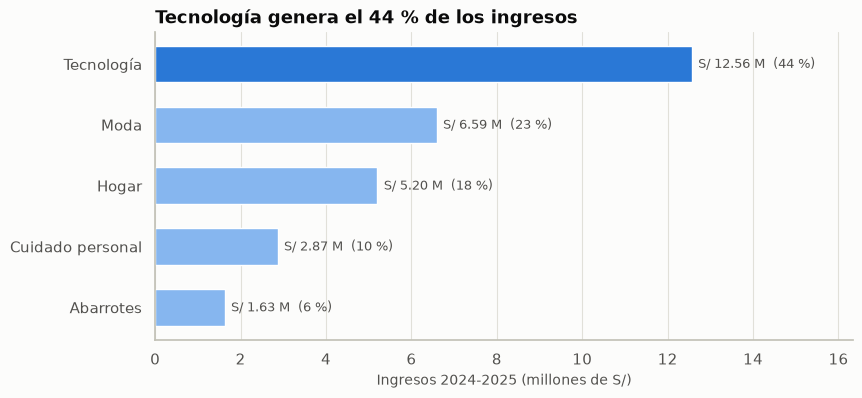

In [48]:
datos = por_categoria.sort_values("ingresos")
lider = datos.index[-1]
fig, ax = plt.subplots(figsize=(9, 4))
colores = [AZUL if c == lider else AZUL_CLARO for c in datos.index]
ax.barh(datos.index.astype(str), datos["ingresos"] / 1e6, color=colores, height=0.6)
for y, (ingreso, pct) in enumerate(zip(datos["ingresos"], datos["participacion_%"])):
    ax.text(ingreso / 1e6 + 0.15, y, f"{millones(ingreso)}  ({pct:.0f} %)", va="center", color=TINTA_2, fontsize=9)
ax.set_title(f"{lider} genera el {datos['participacion_%'].iat[-1]:.0f} % de los ingresos")
ax.set_xlabel("Ingresos 2024-2025 (millones de S/)")
ax.set_ylabel("")
ax.margins(x=0.3)
ax.grid(axis="y", visible=False)
guardar(fig, "01_ingresos_por_categoria")

**Interpretación.** La gráfica destaca a Tecnología, que sola genera casi tanto como Moda, Hogar y Cuidado personal juntas. Abarrotes es la categoría que más se vende, pero la que menos ingresa. Un quiebre de stock en Tecnología es el riesgo comercial más alto.

### 6.2 Evolución mensual de los ingresos (P2)

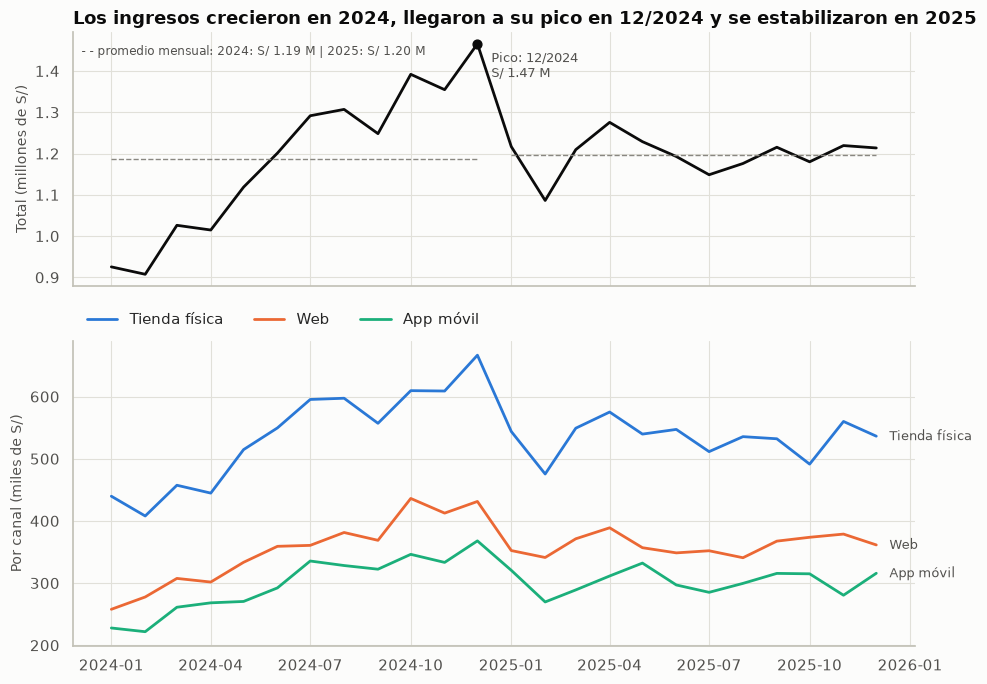

In [49]:
mensual = ventas.pivot_table(index="mes", columns="canal", values="total", aggfunc="sum", observed=True)
mensual_total = mensual.sum(axis=1)
x = mensual.index.to_timestamp()
pico = mensual_total.idxmax()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
ax1.plot(x, mensual_total / 1e6, color=TINTA, lw=2)
ax1.scatter([pico.to_timestamp()], [mensual_total[pico] / 1e6], color=TINTA, s=40, zorder=3)
ax1.annotate(f"Pico: {pico.strftime('%m/%Y')}\n{millones(mensual_total[pico])}",
             (pico.to_timestamp(), mensual_total[pico] / 1e6), xytext=(10, -5),
             textcoords="offset points", color=TINTA_2, fontsize=9, va="top")
promedios = mensual_total.groupby(mensual_total.index.year).mean() / 1e6
for anio, promedio in promedios.items():
    ax1.hlines(promedio, pd.Timestamp(f"{anio}-01-01"), pd.Timestamp(f"{anio}-12-01"),
               color=TENUE, ls="--", lw=1)
ax1.text(0.01, 0.95, "- - promedio mensual: " + " | ".join(f"{a}: S/ {v:.2f} M" for a, v in promedios.items()),
         transform=ax1.transAxes, color=TINTA_2, fontsize=8.5, va="top")
ax1.set_title(f"Los ingresos crecieron en 2024, llegaron a su pico en {pico.strftime('%m/%Y')} "
              f"y se estabilizaron en 2025")
ax1.set_ylabel("Total (millones de S/)")

for canal, color in COLOR_CANAL.items():
    ax2.plot(x, mensual[canal] / 1e3, color=color, lw=2, label=canal)
    ax2.text(x[-1] + pd.Timedelta(days=12), mensual[canal].iat[-1] / 1e3, canal, color=TINTA_2,
             fontsize=9, va="center")
ax2.set_ylabel("Por canal (miles de S/)")
ax2.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3)
ax2.set_xlabel("")
fig.tight_layout()
guardar(fig, "02_ingresos_mensuales")

**Interpretación.** 2024 fue un año de crecimiento sostenido: de S/ 0,93 M en enero a S/ 1,47 M en diciembre. En 2025 los ingresos se estancaron en ~S/ 1,2 M mensuales, sin el crecimiento del segundo semestre de 2024. Los tres canales siguen el mismo patrón, así que la caída no es de un canal en particular.

### 6.3 Distribución del ticket y de la edad (histogramas)

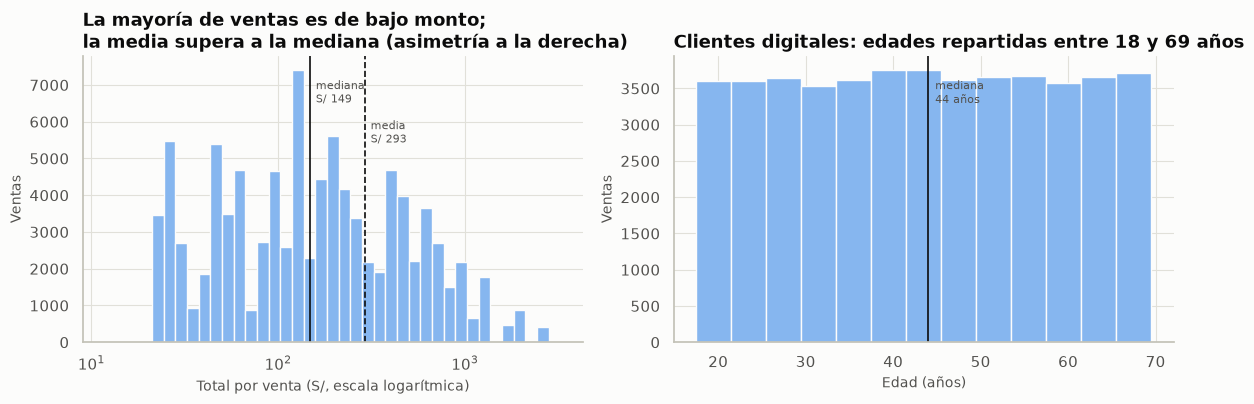

In [50]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

total = ventas["total"].dropna()
bins = np.logspace(np.log10(total.min()), np.log10(total.max()), 40)
ax1.hist(total, bins=bins, color=AZUL_CLARO, edgecolor=FONDO, linewidth=1)
ax1.set_xscale("log")
for valor, nombre, estilo, altura in [(total.median(), "mediana", "-", 0.92), (total.mean(), "media", "--", 0.78)]:
    ax1.axvline(valor, color=TINTA, ls=estilo, lw=1.2)
    ax1.text(valor * 1.07, ax1.get_ylim()[1] * altura, f"{nombre}\nS/ {valor:,.0f}", fontsize=8, color=TINTA_2, va="top")
ax1.set_title("La mayoría de ventas es de bajo monto;\nla media supera a la mediana (asimetría a la derecha)")
ax1.set_xlabel("Total por venta (S/, escala logarítmica)")
ax1.set_ylabel("Ventas")

edad = ventas["edad"].dropna().astype(float)
ax2.hist(edad, bins=np.arange(edad.min() - 0.5, edad.max() + 4, 4), color=AZUL_CLARO, edgecolor=FONDO, linewidth=1)
ax2.axvline(edad.median(), color=TINTA, lw=1.2)
ax2.text(edad.median() + 0.8, ax2.get_ylim()[1] * 0.92, f"mediana\n{edad.median():.0f} años", fontsize=8, color=TINTA_2, va="top")
ax2.set_title(f"Clientes digitales: edades repartidas entre {edad.min():.0f} y {edad.max():.0f} años")
ax2.set_xlabel("Edad (años)")
ax2.set_ylabel("Ventas")
fig.tight_layout()
guardar(fig, "03_histogramas_ticket_edad")

**Interpretación.** El ticket tiene asimetría a la derecha: se concentra entre S/ 50 y S/ 400 y tiene una cola larga de compras de más de S/ 1 000. Por eso la media (S/ 293) casi duplica a la mediana (S/ 149). La edad de los clientes digitales es casi uniforme: no hay un grupo de edad dominante al que dirigir la comunicación.

### 6.4 Ticket por categoría (boxplot)

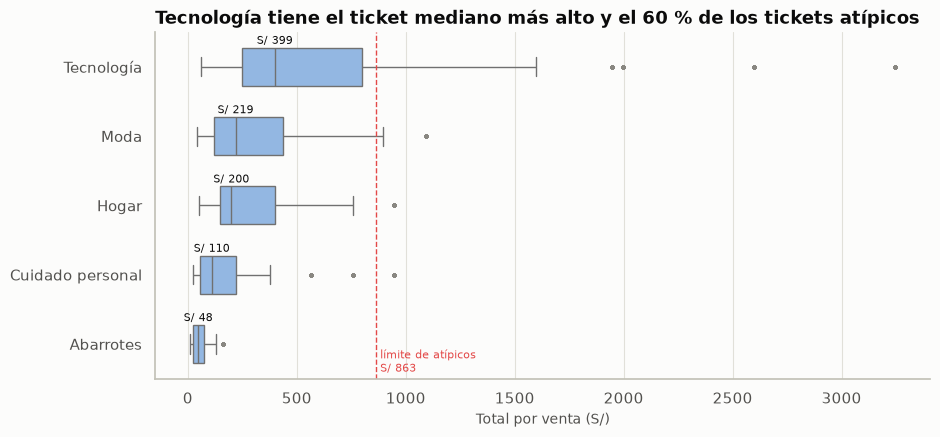

In [51]:
orden = ventas.groupby("categoria", observed=True)["total"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=ventas, x="total", y="categoria", order=orden, color=AZUL_CLARO, width=0.55,
            fliersize=2, linewidth=1, flierprops={"markeredgecolor": TENUE}, ax=ax)
for y, categoria in enumerate(orden):
    mediana = ventas.loc[ventas["categoria"] == categoria, "total"].median()
    ax.text(mediana, y - 0.33, f"S/ {mediana:,.0f}", ha="center", fontsize=8, color=TINTA)
ax.axvline(limite_atipico, color=ROJO, ls="--", lw=1)
ax.text(limite_atipico + 20, len(orden) - 0.6, f"límite de atípicos\nS/ {limite_atipico:,.0f}", color=ROJO, fontsize=8)
pct_atipicos = ventas.loc[ventas["ticket_atipico"], "categoria"].value_counts(normalize=True)[orden[0]] * 100
ax.set_title(f"{orden[0]} tiene el ticket mediano más alto y el {pct_atipicos:.0f} % de los tickets atípicos")
ax.set_xlabel("Total por venta (S/)")
ax.set_ylabel("")
guardar(fig, "04_boxplot_ticket_categoria")

**Interpretación.** Tecnología tiene la caja más ancha y la mediana más alta (S/ 399), así que sus ventas son las más variables y concentra la mayoría de los tickets por encima de S/ 863. Abarrotes tiene tickets bajos y muy concentrados. Las cinco categorías se comportan como negocios distintos y conviene seguirlas con KPI separados.

### 6.5 Ubicación de las ventas por distrito (P3, scatterplot geoespacial)

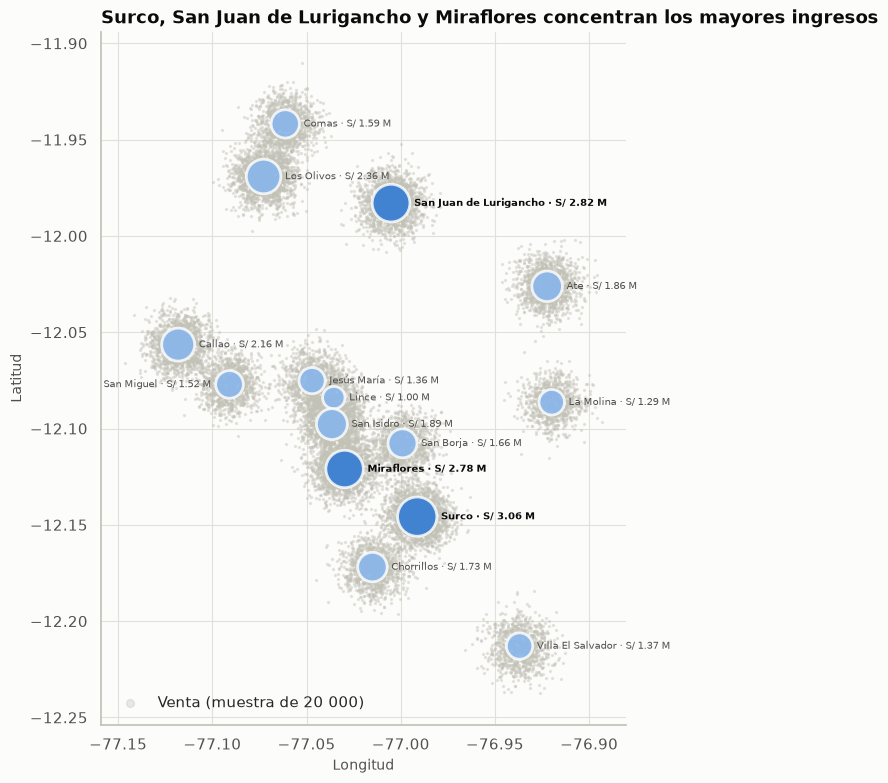

In [52]:
centros_distrito = ventas.dropna(subset=["latitud", "longitud", "distrito"]).groupby("distrito", observed=True).agg(
    lat=("latitud", "median"), lon=("longitud", "median"), ingresos=("total", "sum"))
muestra = ventas.dropna(subset=["latitud", "longitud"]).sample(20000, random_state=1)
top = centros_distrito["ingresos"].nlargest(3).index

fig, ax = plt.subplots(figsize=(8.5, 9))
ax.scatter(muestra["longitud"], muestra["latitud"], s=2, color=GRIS, alpha=0.35, label="Venta (muestra de 20 000)")
tamanos = centros_distrito["ingresos"] / centros_distrito["ingresos"].max() * 800
colores = [AZUL if d in top else AZUL_CLARO for d in centros_distrito.index]
ax.scatter(centros_distrito["lon"], centros_distrito["lat"], s=tamanos, color=colores, alpha=0.85,
           edgecolor=FONDO, linewidth=2)
A_LA_IZQUIERDA = {"San Miguel"}  # etiqueta a la izquierda para que no choque con Jesús María
for distrito, fila in centros_distrito.iterrows():
    lado = -1 if distrito in A_LA_IZQUIERDA else 1
    ax.annotate(f"{distrito} · {millones(fila['ingresos'])}", (fila["lon"], fila["lat"]),
                xytext=(lado * (np.sqrt(tamanos[distrito]) / 2 + 3), 0), textcoords="offset points",
                ha="right" if lado < 0 else "left", va="center", fontsize=7.5, color=TINTA if distrito in top else TINTA_2,
                fontweight="bold" if distrito in top else "normal")
ax.set_aspect(1 / np.cos(np.radians(12)))  # misma escala en km para latitud y longitud
ax.set_title(f"{top[0]}, {top[1]} y {top[2]} concentran los mayores ingresos")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.legend(loc="lower left", markerscale=4)
guardar(fig, "05_mapa_distritos")

**Interpretación.** Las ventas se agrupan en 15 núcleos que coinciden con los distritos. Los de mayor ingreso son Surco y Miraflores, en Lima Moderna, y San Juan de Lurigancho, en Lima Este. Lince, La Molina y Jesús María son los que menos aportan. La demanda no se limita a los distritos de mayor nivel socioeconómico, lo que es relevante para planificar rutas de delivery y la ubicación de tiendas.

### 6.6 Correlaciones entre variables numéricas (heatmap)

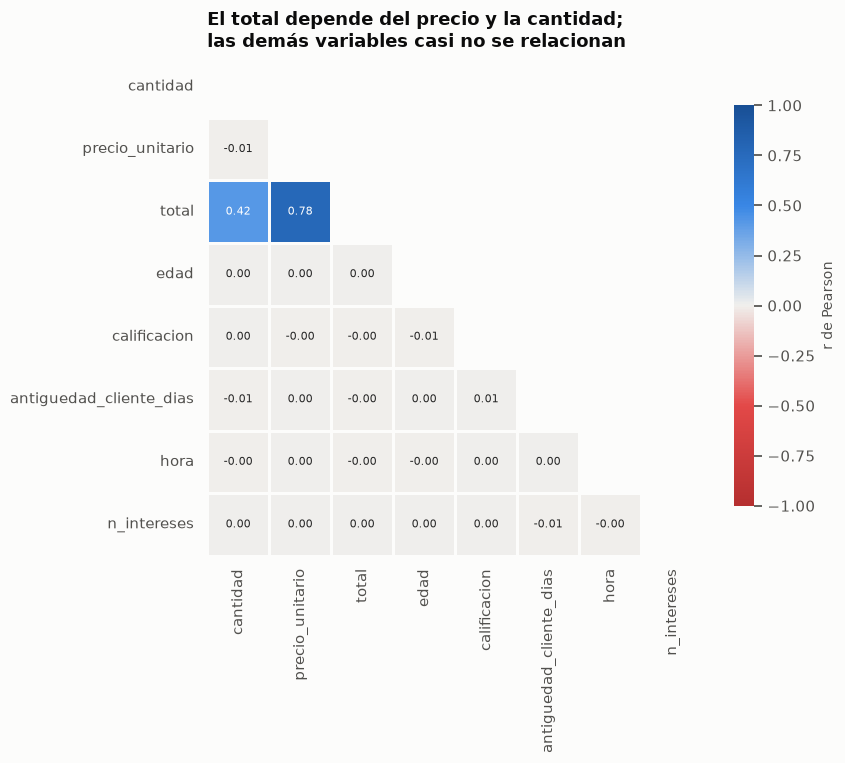

In [53]:
mascara = np.triu(np.ones(pearson.shape, dtype=bool))
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(pearson, mask=mascara, cmap=DIVERGENTE, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, linewidths=2, linecolor=FONDO, cbar_kws={"label": "r de Pearson", "shrink": 0.8}, ax=ax)
ax.set_title("El total depende del precio y la cantidad;\nlas demás variables casi no se relacionan")
ax.grid(False)
guardar(fig, "06_heatmap_correlaciones")

**Interpretación.** El único bloque con color es el que forman total, precio y cantidad, que se relacionan por definición. Todo lo demás es gris (r ≈ 0): la calificación no sube ni baja con el monto, la edad o la antigüedad del cliente. La satisfacción hay que explicarla con otras variables, como los temas de los comentarios.

### 6.7 Ventas por hora y canal (P2, heatmap)

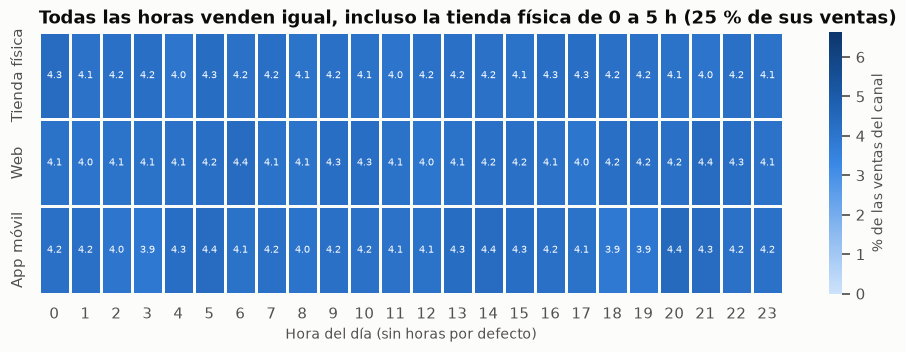

In [54]:
# % de las ventas de cada canal en cada hora; si fueran parejas, cada hora tendría 100/24 = 4.2 %
canal_hora = pd.crosstab(ventas["canal"], ventas["hora"], normalize="index").mul(100).loc[list(COLOR_CANAL)]
madrugada_tienda = canal_hora.loc["Tienda física", 0:5].sum()
fig, ax = plt.subplots(figsize=(12, 3.4))
sns.heatmap(canal_hora, cmap=SECUENCIAL, vmin=0, vmax=canal_hora.values.max() * 1.5, annot=True, fmt=".1f",
            annot_kws={"fontsize": 7.5}, linewidths=1, linecolor=FONDO,
            cbar_kws={"label": "% de las ventas del canal"}, ax=ax)
ax.set_title(f"Todas las horas venden igual, incluso la tienda física de 0 a 5 h ({madrugada_tienda:.0f} % de sus ventas)")
ax.set_xlabel("Hora del día (sin horas por defecto)")
ax.set_ylabel("")
ax.grid(False)
guardar(fig, "07_heatmap_hora_canal")

**Interpretación.** Cada hora tiene ~4,2 % de las ventas en los tres canales, es decir, un reparto perfectamente plano. En web y app es posible, pero que la **tienda física registre una de cada cuatro ventas entre la medianoche y las 5 a. m.** no es creíble. Junto con la hora por defecto (`10:00`), esto indica que la hora guardada no es la hora real de la compra (podría ser la hora en que se sincroniza el registro). **Antes de decidir horarios de personal o de campañas, hay que corregir cómo se registra la hora.**

### 6.8 Métodos de pago por canal (P4)

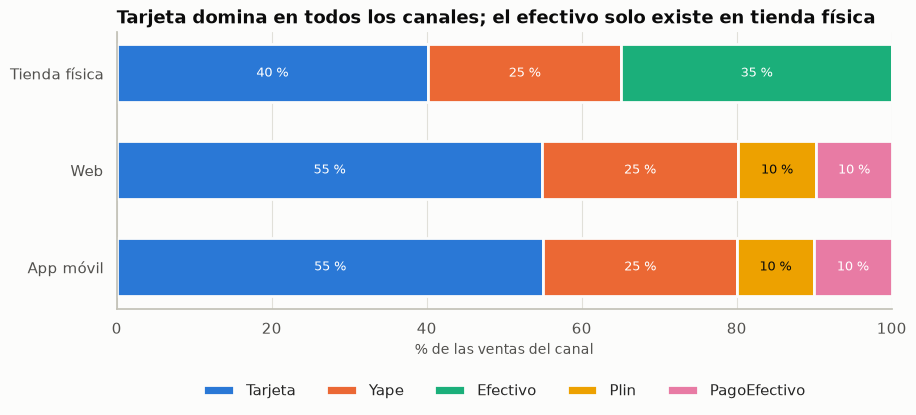

In [55]:
pagos = pd.crosstab(ventas["canal"], ventas["metodo_pago"], normalize="index").mul(100)
pagos = pagos[list(COLOR_PAGO)].loc[list(COLOR_CANAL)[::-1]]
fig, ax = plt.subplots(figsize=(10, 3.6))
izquierda = np.zeros(len(pagos))
for metodo, color in COLOR_PAGO.items():
    valores = pagos[metodo].to_numpy()
    ax.barh(pagos.index, valores, left=izquierda, color=color, edgecolor=FONDO, linewidth=2, height=0.6, label=metodo)
    for y, (inicio, valor) in enumerate(zip(izquierda, valores)):
        if valor >= 6:
            ax.text(inicio + valor / 2, y, f"{valor:.0f} %", ha="center", va="center", fontsize=9,
                    color=TINTA if metodo == "Plin" else "white")
    izquierda += valores
ax.set_title("Tarjeta domina en todos los canales; el efectivo solo existe en tienda física")
ax.set_xlabel("% de las ventas del canal")
ax.set_xlim(0, 100)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.22))
ax.grid(axis="y", visible=False)
guardar(fig, "08_metodos_pago_por_canal")

**Interpretación.** La tarjeta es el medio principal en todos los canales. Yape tiene el mismo peso (25 %) en la tienda y en lo digital. En tienda física el efectivo reemplaza a Plin y PagoEfectivo, que no se ofrecen. Incorporar Plin en caja y mantener Yape en todos los canales cubre las preferencias que ya muestran los clientes.

### 6.9 Temas y sentimiento de los comentarios (P5)

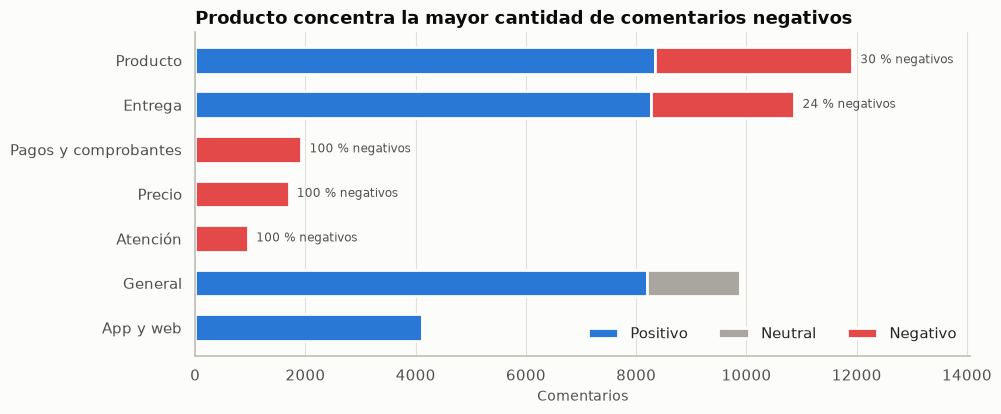

In [56]:
temas = pd.crosstab(ventas["tema_comentario"], ventas["sentimiento"])[list(COLOR_SENTIMIENTO)]
temas = temas.loc[temas["Negativo"].sort_values().index]
peor = temas["Negativo"].idxmax()
fig, ax = plt.subplots(figsize=(10, 4.2))
izquierda = np.zeros(len(temas))
for sentimiento_, color in COLOR_SENTIMIENTO.items():
    valores = temas[sentimiento_].to_numpy()
    ax.barh(temas.index.astype(str), valores, left=izquierda, color=color, edgecolor=FONDO,
            linewidth=2, height=0.6, label=sentimiento_)
    izquierda += valores
for y, (n_negativos, n_total) in enumerate(zip(temas["Negativo"], temas.sum(axis=1))):
    if n_negativos == 0:
        continue
    ax.text(n_total + 150, y, f"{n_negativos / n_total * 100:.0f} % negativos", va="center", fontsize=8.5, color=TINTA_2)
ax.set_title(f"{peor} concentra la mayor cantidad de comentarios negativos")
ax.set_xlabel("Comentarios")
ax.margins(x=0.18)
ax.legend(ncol=3, loc="lower right")
ax.grid(axis="y", visible=False)
guardar(fig, "09_temas_sentimiento")

**Interpretación.** El 26 % de los comentarios es negativo. Por volumen, las quejas más frecuentes son de **producto** (empaque golpeado, tallas que no corresponden, productos fallados) y de **entrega** (demoras). Los temas de **pagos y comprobantes** (cobros dobles, boletas que no llegan), precio y atención generan solo quejas: son fallas operativas que no tienen contraparte positiva.

### 6.10 Aporte de cada segmento de clientes (P6)

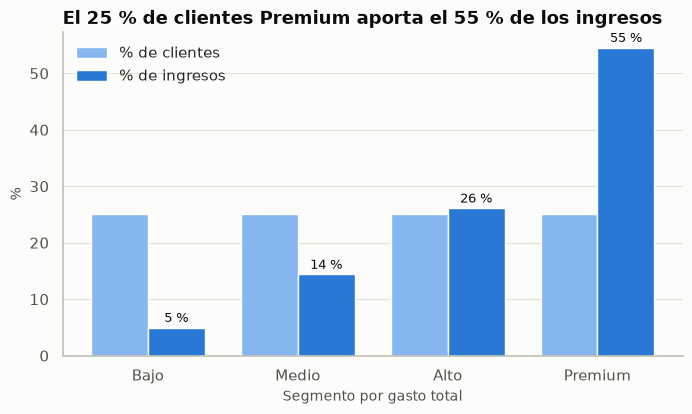

In [57]:
fig, ax = plt.subplots(figsize=(8, 4.2))
posiciones = np.arange(len(por_segmento))
ancho = 0.38
ax.bar(posiciones - ancho / 2, por_segmento["clientes_%"], ancho, color=AZUL_CLARO, label="% de clientes")
ax.bar(posiciones + ancho / 2, por_segmento["ingresos_%"], ancho, color=AZUL, label="% de ingresos")
for x_, valor in zip(posiciones + ancho / 2, por_segmento["ingresos_%"]):
    ax.text(x_, valor + 1, f"{valor:.0f} %", ha="center", fontsize=9, color=TINTA)
ax.set_xticks(posiciones, por_segmento.index.astype(str))
ax.set_title(f"El 25 % de clientes Premium aporta el {por_segmento['ingresos_%'].iat[-1]:.0f} % de los ingresos")
ax.set_ylabel("%")
ax.set_xlabel("Segmento por gasto total")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
guardar(fig, "10_segmentos_clientes")

**Interpretación.** La distribución de ingresos es muy desigual: un cuarto de los clientes genera más de la mitad de los ingresos, y la mitad con menor gasto aporta apenas el 19 %. Retener a los clientes Premium y llevar a los del segmento Alto a Premium tiene más impacto que atraer clientes nuevos de bajo gasto.

## 7. Interpretación y hallazgos para Ambar Company

### 7.1 Calidad de los datos

Antes de la limpieza, el 34 % de las filas tenía al menos un problema: duplicados, fechas en dos formatos, 39 variantes de distrito, precios x100, totales que no cuadraban y JSON cortados. Sin el proceso de limpieza, los KPI estarían inflados (duplicados y precios erróneos) o partidos (distritos y métodos de pago mal escritos). El dataset limpio pasa todas las reglas de formato, catálogo, rango y coherencia, y lo que no se pudo corregir quedó en `REPORTE_NO_CORREGIDOS.csv` para corregirlo en el origen.

### 7.2 Principales hallazgos

1. **Los ingresos dependen de pocos productos y pocos clientes.** Tecnología aporta el 44 % de los ingresos (S/ 12,6 M de S/ 28,9 M), el Monitor 24" por sí solo el 18 %, y el 25 % de clientes Premium el 55 %.
2. **El crecimiento se detuvo en 2025.** Tras crecer durante todo 2024 hasta su pico en diciembre (S/ 1,47 M), los ingresos se estabilizaron en ~S/ 1,2 M por mes. 2025 cerró solo +0,8 % sobre 2024 y su segundo semestre quedó por debajo del de 2024 en los tres canales.
3. **Lo digital ya es la mayoría.** Web y app suman el 55 % de los ingresos con el mismo ticket que la tienda, así que el cliente gasta lo mismo por cualquier canal.
4. **La demanda está repartida en Lima.** Surco, San Juan de Lurigancho y Miraflores lideran, pero ningún distrito pasa del 11 %.
5. **La satisfacción es buena (3,85/5), pero no depende del producto ni del canal.** Es igual en todas las categorías, canales y distritos. Lo que la baja son fallas puntuales: producto dañado o equivocado, demoras en la entrega, cobros dobles y boletas que no llegan.
6. **La hora de las ventas no es confiable.** El 6 % tiene una hora por defecto y la tienda física registra ventas de madrugada al mismo ritmo que de día.

### 7.3 Implicancias y decisiones para Ambar Company

| Hallazgo | Implicancia | Decisión propuesta |
|---|---|---|
| Tecnología = 44 % de los ingresos | Un quiebre de stock en monitores o smartwatches golpea directamente los ingresos | Priorizar la reposición y la negociación con proveedores de Tecnología; vender accesorios junto con esos productos para aprovechar su ticket |
| Abarrotes: muchas ventas y poco ingreso | Trae tráfico, pero aporta poco margen en soles | Usarlo como gancho en promociones combinadas con categorías de mayor ticket |
| Estancamiento en 2025 | Se perdió el impulso de 2024 | Revisar qué campañas se hicieron en el segundo semestre de 2024 y repetirlas; fijar una meta de crecimiento mensual y seguirla con este análisis |
| 25 % de clientes = 55 % de ingresos | Perder clientes Premium cuesta más de la mitad del negocio | Programa de fidelización para Premium y Alto, con alertas cuando aumentan los días desde su última compra |
| Digital = 55 % de los ingresos | El canal digital ya es el principal | Invertir en la experiencia de web y app (sus comentarios son 100 % positivos) y ofrecer en ellos los mismos medios de pago que usa el cliente |
| Quejas de producto, entrega y pagos | Bajan la satisfacción sin importar qué se compre | Control de empaque y tallas antes del despacho; meta de plazo de entrega; conciliación diaria de cobros con tarjeta y envío automático de boletas |
| Hora poco confiable y 34 % de filas con errores | Las decisiones por horario o por zona pueden partir de datos falsos | Validar en el sistema de origen (formatos, catálogos, hora real) y usar `REPORTE_NO_CORREGIDOS.csv` como lista de correcciones |

### 7.4 Siguientes pasos

Con el dataset ya confiable, la siguiente iteración de CRISP-DM puede pasar a modelos: pronóstico de ventas mensuales, segmentación RFM con *k-means* y predicción de clientes Premium en riesgo de dejar de comprar.

## 8. Archivos generados

| Archivo | Contenido |
|---|---|
| `datos/CL/ARCHIVO_CL.csv` | Dataset limpio |
| `reporte/REPORTE_NO_CORREGIDOS.csv` | Filas con datos que no se pudieron corregir, con sus valores originales y el motivo |
| `graficos/*.png` | Gráficos de la sección 6 |